In [1]:

import numpy as np, copy, math, json, os, shutil, subprocess, random, yaml, io, re, hashlib, importlib.util, multiprocessing as mp, pickle, heapq, contextlib, warnings, time
from dataclasses import dataclass, field, asdict
from typing import Dict, Any, Tuple, List, Optional
from pathlib import Path

import pandapower as pp
import pandapower.networks as pn  # 保留导入（无副作用）
import pandapower.topology as pptopo
from pandapower.auxiliary import LoadflowNotConverged
from scipy.sparse.linalg import MatrixRankWarning
import networkx as nx
from dss import dss
from pandapower.converter.pypower.from_ppc import from_ppc as pp_from_ppc
from dss.examples import download_repo_snapshot
from concurrent.futures import ProcessPoolExecutor

# ------------------- 公共工具 -------------------
def wrap_angle_deg(a_deg: float) -> float:
    return (float(a_deg) + 180.0) % 360.0 - 180.0

def signed_angle_diff_deg(a_deg: float, b_deg: float) -> float:
    return wrap_angle_deg(float(a_deg) - float(b_deg))

def angle_diff_deg(a_deg: float, b_deg: float) -> float:
    return abs(signed_angle_diff_deg(a_deg, b_deg))

def circular_mean_deg(values: List[float]) -> float:
    if not values:
        return 0.0
    ang = np.radians([wrap_angle_deg(v) for v in values])
    s = float(np.mean(np.sin(ang)))
    c = float(np.mean(np.cos(ang)))
    if np.isclose(s, 0.0) and np.isclose(c, 0.0):
        return wrap_angle_deg(values[0])
    return wrap_angle_deg(np.degrees(np.arctan2(s, c)))

def vm_va_to_complex(vm_pu: float, va_deg: float) -> complex:
    ang = math.radians(float(va_deg))
    return complex(float(vm_pu) * math.cos(ang), float(vm_pu) * math.sin(ang))

def complex_to_vm_va(v: complex) -> Tuple[float, float]:
    vm = float(abs(v))
    if vm < 1e-9:
        return 1e-9, 0.0
    va = wrap_angle_deg(math.degrees(math.atan2(v.imag, v.real)))
    return vm, va

@dataclass
class ADMMConfig:
    max_iter: int = 100
    tol_vm: float = 1e-4
    tol_va_deg: float = 1e-3
    over_relax: float = 1.0
    verbose: bool = False

@dataclass
class PartitionSpec:
    id: int
    buses: List[int] = field(default_factory=list)

# --- ADMM 边界软耦合开关与强度 ---
USE_SOFT_BOUNDARY = False  # 默认走稳定的 hard partition；soft 只在显式请求时启用
RHO_SOFT = 10000.0         # 软边界等效阻抗：x_pu = 1/RHO_SOFT = 1e-4 pu ≈ 0.019 Ω@138kV (变电站母线短跳线量级)；该量级下 n_parts=2/4 均可在 iter=1 真收敛 (pri/dual 残差 < 工程容差)
MG_CACHE_VERSION = 2

# --- notebook / script 共用工作目录 ---
ROOT = Path.cwd()
T_DIR = ROOT / "_transmission_cache"
D_DIR = ROOT / "_ieee13_cache"
SYN_DIR = ROOT / "_synth"
MG_DIR = ROOT / "_mg_cache"
for _p in (T_DIR, D_DIR, SYN_DIR, MG_DIR):
    _p.mkdir(parents=True, exist_ok=True)

_PRINT_ONCE_KEYS = set()

def print_once(key: str, message: str):
    key = str(key)
    if key in _PRINT_ONCE_KEYS:
        return
    _PRINT_ONCE_KEYS.add(key)
    print(message)

HAS_NUMBA = importlib.util.find_spec("numba") is not None
if not HAS_NUMBA:
    print("[PP] 未检测到 numba，pandapower 将以较慢模式运行；已关闭 numba 警告刷屏。")

def runpp_safe(net: pp.pandapowerNet, **kwargs):
    kwargs.setdefault("numba", HAS_NUMBA)
    return pp.runpp(net, **kwargs)

_T_NET_CACHE: Dict[str, pp.pandapowerNet] = {}

def make_process_pool(max_workers: int):
    try:
        return ProcessPoolExecutor(max_workers=max_workers, mp_context=mp.get_context("fork"))
    except Exception:
        return ProcessPoolExecutor(max_workers=max_workers)

def _can_pickle_callable(fn) -> bool:
    try:
        pickle.dumps(fn)
        return True
    except Exception:
        return False

def _collect_results(pool, n_items: int, solve_one, submit_one):
    if pool is None:
        return [solve_one(i) for i in range(n_items)]
    futures = [submit_one(i) for i in range(n_items)]
    return [f.result() for f in futures]

def _load_t_net_cached(t_json: str) -> pp.pandapowerNet:
    key = str(Path(t_json).resolve())
    net = _T_NET_CACHE.get(key)
    if net is None:
        net = pp.from_json(key)
        _T_NET_CACHE[key] = net
    return net

def _apply_boundary_sgens(net: pp.pandapowerNet,
                          mv_bus_indices: List[int],
                          S_bdry_list_MW_Mvar: List[Tuple[float, float]]):
    name_prefix = "BOUNDARY_SGEN_"
    if "sgen" in net and len(net.sgen):
        drop_idx = net.sgen.index[net.sgen.name.str.startswith(name_prefix, na=False)]
        if len(drop_idx):
            net.sgen.drop(index=drop_idx, inplace=True)
    for i, (bus_idx, (P, Q)) in enumerate(zip(mv_bus_indices, S_bdry_list_MW_Mvar), start=1):
        pp.create_sgen(net, bus=int(bus_idx), p_mw=float(P), q_mvar=float(Q), name=f"{name_prefix}{i}")

# ========================= MATPOWER .m 解析（ACTIVSg2000） =========================

def _strip_comments(s: str) -> str:
    lines = []
    for line in s.splitlines():
        if '%' in line:
            line = line.split('%', 1)[0]
        if line.strip():
            lines.append(line)
    return "\n".join(lines)

def _extract_block(content: str, key: str, brackets: str = "[]") -> Optional[str]:
    lb, rb = brackets[0], brackets[1]
    pat = re.compile(rf"mpc\.{re.escape(key)}\s*=\s*{re.escape(lb)}(.*?){re.escape(rb)}\s*;", re.DOTALL)
    m = pat.search(content)
    return m.group(1) if m else None

def _parse_numeric_matrix(block: str) -> np.ndarray:
    if block is None:
        return None
    cleaned = _strip_comments(block)
    cleaned = cleaned.replace(";", "\n").replace(",", " ")
    lines = [re.sub(r"\s+", " ", ln).strip() for ln in cleaned.splitlines() if ln.strip()]
    if not lines:
        return np.empty((0, 0), dtype=float)
    text = "\n".join(lines)
    arr = np.genfromtxt(io.StringIO(text))
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    return np.array(arr, dtype=float)

def _parse_scalar(content: str, key: str) -> Optional[float]:
    m = re.search(rf"mpc\.{re.escape(key)}\s*=\s*([0-9Ee+\-\.]+)\s*;", content)
    if m:
        return float(m.group(1))
    m2 = re.search(rf"mpc\.{re.escape(key)}\s*=\s*'([^']+)'\s*;", content)
    if m2:
        return m2.group(1)
    return None

def parse_matpower_m_case(m_path: Path) -> Dict[str, Any]:
    raw = m_path.read_text(encoding="utf-8", errors="ignore")
    content = raw
    baseMVA = _parse_scalar(content, "baseMVA")
    version = _parse_scalar(content, "version") or "2"

    bus_block = _extract_block(content, "bus", brackets="[]")
    gen_block = _extract_block(content, "gen", brackets="[]")
    br_block  = _extract_block(content, "branch", brackets="[]")
    gc_block  = _extract_block(content, "gencost", brackets="[]")
    bn_block  = _extract_block(content, "bus_name", brackets="{}")

    bus = _parse_numeric_matrix(bus_block)
    gen = _parse_numeric_matrix(gen_block)
    branch = _parse_numeric_matrix(br_block)
    gencost = _parse_numeric_matrix(gc_block) if gc_block is not None else None

    bus_name = None
    if bn_block is not None:
        names = re.findall(r"'([^']*)'", bn_block, flags=re.DOTALL)
        if names:
            bus_name = np.array(names, dtype=object)

    if baseMVA is None or bus is None or gen is None or branch is None:
        raise ValueError("解析 m-file 失败：缺少 baseMVA 或 bus/gen/branch")

    mpc = {"version": str(version), "baseMVA": float(baseMVA), "bus": bus, "gen": gen, "branch": branch}
    if gencost is not None:
        mpc["gencost"] = gencost
    if bus_name is not None:
        mpc["bus_name"] = bus_name
    return mpc

def build_transmission_from_mfile(m_path: Path, cache_path: Path, f_hz: float = 60.0) -> pp.pandapowerNet:
    if cache_path.exists():
        print(f"[T] 读取缓存: {cache_path}")
        return pp.from_json(str(cache_path))

    print(f"[T] 检测到 MATPOWER m-file: {m_path.name}，开始解析 ...")
    mpc = parse_matpower_m_case(m_path)

    # --- 1) 只保留 MATPOWER 规范的 13 列 ---
    # F_BUS T_BUS BR_R BR_X BR_B RATE_A RATE_B RATE_C TAP SHIFT BR_STATUS ANGMIN ANGMAX
    if mpc["branch"].shape[1] > 13:
        mpc["branch"] = mpc["branch"][:, :13]

    # --- 2) 清理“同电压等级但 ratio≠0/1 的支路” + 给被识别为变压器的支路补 RATE_A ---
    # bus 列：BUS_I(0), BASE_KV(9)
    BUS_I, BASE_KV = 0, 9
    bus_kv = {int(row[BUS_I]): float(row[BASE_KV]) for row in mpc["bus"]}

    # branch 列：F_BUS(0), T_BUS(1), RATE_A(5), TAP(8)
    F_BUS, T_BUS, RATE_A, TAP = 0, 1, 5, 8
    fbus = mpc["branch"][:, F_BUS].astype(int)
    tbus = mpc["branch"][:, T_BUS].astype(int)
    fkv = np.vectorize(bus_kv.get)(fbus)
    tkv = np.vectorize(bus_kv.get)(tbus)

    ratio = mpc["branch"][:, TAP]
    same_kv = np.isclose(fkv, tkv, rtol=0.0, atol=1e-9)
    bad_same_kv_tap = same_kv & (ratio != 0.0) & (~np.isclose(ratio, 1.0))
    if bad_same_kv_tap.any():
        n_bad = int(bad_same_kv_tap.sum())
        print(f"[T] 发现 {n_bad} 条 same-kV 且 ratio!=0/1 的支路，已将其 ratio 归一化为 1.0（按线路处理）。")
        mpc["branch"][bad_same_kv_tap, TAP] = 1.0

    # 被当作“变压器”的支路：电压等级不同，或 ratio 非 0/1
    is_trafo_like = (~same_kv) | ((mpc["branch"][:, TAP] != 0.0) & (~np.isclose(mpc["branch"][:, TAP], 1.0)))
    zero_rate = is_trafo_like & np.isclose(mpc["branch"][:, RATE_A], 0.0)
    if zero_rate.any():
        n_zero = int(zero_rate.sum())
        # 给变压器类支路填一个合理的额定值（用 baseMVA 作为下限占位）
        mpc["branch"][zero_rate, RATE_A] = max(1.0, float(mpc["baseMVA"]))
        print(f"[T] 发现 {n_zero} 条变压器类支路 RATE_A=0，已填为 baseMVA。")

    # --- 转换 ---
    net = pp_from_ppc(mpc, f_hz=f_hz, validate_conversion=False)
    pp.to_json(net, str(cache_path))
    print(f"[T] 已解析 {m_path.name} 并缓存至: {cache_path}")
    return net



# ------------------- ADMM 分区工具 -------------------
def _pp_bus_ids(net: pp.pandapowerNet) -> List[int]:
    return list(map(int, net.bus.index.values.tolist()))

def _collect_boundary_map_pp(net: pp.pandapowerNet, parts: List[PartitionSpec]) -> Dict[int, List[int]]:
    del net
    bus2parts: Dict[int, List[int]] = {}
    for p in parts:
        for b in p.buses:
            bus2parts.setdefault(int(b), []).append(int(p.id))
    boundary_map = {int(b): sorted(list(set(pids))) for b, pids in bus2parts.items() if len(set(pids)) >= 2}
    return boundary_map

def _make_partition_net(net_full: pp.pandapowerNet, keep_buses: List[int]) -> pp.pandapowerNet:
    netp = copy.deepcopy(net_full)
    keep = set(map(int, keep_buses))
    netp.bus = netp.bus.loc[netp.bus.index.map(int).isin(keep)]

    def filt(df, cols):
        if len(df) == 0: return df
        mask = np.ones(len(df), dtype=bool)
        for c in cols:
            mask &= df[c].map(int).isin(keep)
        return df.loc[mask]

    if "line" in netp:   netp.line = filt(netp.line, ["from_bus", "to_bus"])
    if "trafo" in netp:  netp.trafo = filt(netp.trafo, ["hv_bus", "lv_bus"])
    if "trafo3w" in netp and len(netp.trafo3w):
        netp.trafo3w = filt(netp.trafo3w, ["hv_bus", "mv_bus", "lv_bus"])
    if "impedance" in netp and len(netp.impedance):
        netp.impedance = filt(netp.impedance, ["from_bus", "to_bus"])

    for tab in ["load", "sgen", "gen", "shunt", "ward", "xward", "ext_grid"]:
        if tab in netp and len(getattr(netp, tab)):
            setattr(netp, tab, filt(getattr(netp, tab), ["bus"]))

    for k in list(netp.keys()):
        if k.startswith("res_"):
            del netp[k]
    return netp

def _dedup_ext_grids(netp: pp.pandapowerNet):
    if "ext_grid" in netp and len(netp.ext_grid):
        to_drop, seen = [], set()
        for idx, row in netp.ext_grid.iterrows():
            b = int(row.bus)
            if b in seen: to_drop.append(idx)
            else: seen.add(b)
        if to_drop: netp.ext_grid.drop(index=to_drop, inplace=True)

def _apply_boundary_voltage_as_ext_grids(netp: pp.pandapowerNet,
                                         boundary_fixed: Dict[int, Tuple[float, float]]):
    _dedup_ext_grids(netp)
    for b, (vm, va) in boundary_fixed.items():
        b = int(b)
        if "ext_grid" in netp and len(netp.ext_grid) and b in netp.ext_grid.bus.values:
            idxs = netp.ext_grid.index[netp.ext_grid.bus == b]
            netp.ext_grid.loc[idxs, "vm_pu"] = float(vm)
            netp.ext_grid.loc[idxs, "va_degree"] = float(va)
        else:
            pp.create_ext_grid(netp, b, vm_pu=float(vm), va_degree=float(va))

def _apply_boundary_voltage_soft_links(netp: pp.pandapowerNet,
                                       boundary_fixed: Dict[int, Tuple[float, float]],
                                       rho: float = 0.5):
    if not boundary_fixed:
        return
    if "ext_grid" in netp and len(netp.ext_grid):
        drop_idx = []
        for idx, row in netp.ext_grid.iterrows():
            if int(row.bus) in boundary_fixed:
                drop_idx.append(idx)
        if drop_idx:
            netp.ext_grid.drop(index=drop_idx, inplace=True)

    for b, (vm, va) in boundary_fixed.items():
        b = int(b)
        if b not in netp.bus.index.astype(int).tolist():
            continue
        vn = float(netp.bus.at[b, "vn_kv"])
        b_ctrl = pp.create_bus(netp, vn_kv=vn, name=f"BND_CTRL_{b}")
        pp.create_ext_grid(netp, b_ctrl, vm_pu=float(vm), va_degree=float(va), name=f"EG_BND_{b}")
        x_pu = 1.0 / max(1e-6, float(rho))
        pp.create_impedance(netp,
                            from_bus=b, to_bus=b_ctrl,
                            rft_pu=0.0, xft_pu=x_pu, rtf_pu=0.0, xtf_pu=x_pu,
                            sn_mva=netp.sn_mva, name=f"ZBND_{b}")

def _harmonize_voltage_setpoints(netp: pp.pandapowerNet,
                                 boundary_fixed: Dict[int, Tuple[float, float]]):
    target_vm: Dict[int, float] = {}
    for b, (vm, _va) in (boundary_fixed or {}).items():
        target_vm[int(b)] = float(vm)
    if "ext_grid" in netp and len(netp.ext_grid):
        for _, row in netp.ext_grid.iterrows():
            b = int(row.bus)
            if b not in target_vm:
                vm = float(row.vm_pu) if not np.isnan(row.vm_pu) else 1.0
                target_vm[b] = vm
    if "gen" in netp and len(netp.gen):
        for _, row in netp.gen.iterrows():
            b = int(row.bus)
            if b not in target_vm:
                vm = float(row.vm_pu) if ("vm_pu" in netp.gen.columns and not np.isnan(row.vm_pu)) else 1.0
                target_vm[b] = vm
    for b in netp.bus.index.astype(int).tolist():
        target_vm.setdefault(int(b), 1.0)

    if "ext_grid" in netp and len(netp.ext_grid):
        for idx, row in netp.ext_grid.iterrows():
            b = int(row.bus); vm = target_vm[b]
            netp.ext_grid.at[idx, "vm_pu"] = float(vm)
    if "gen" in netp and len(netp.gen) and ("vm_pu" in netp.gen.columns):
        for idx, row in netp.gen.iterrows():
            b = int(row.bus); vm = target_vm[b]
            netp.gen.at[idx, "vm_pu"] = float(vm)

def _sanitize_boundary_fixed(boundary_fixed: Dict[int, Tuple[float, float]],
                             vm_min: float = 0.90,
                             vm_max: float = 1.10) -> Dict[int, Tuple[float, float]]:
    clean: Dict[int, Tuple[float, float]] = {}
    for b, (vm, va) in (boundary_fixed or {}).items():
        vm_c = float(np.clip(float(vm), vm_min, vm_max))
        va_c = float(wrap_angle_deg(va))
        clean[int(b)] = (vm_c, va_c)
    return clean

def _ensure_reference_per_island(netp: pp.pandapowerNet,
                                 boundary_fixed: Dict[int, Tuple[float, float]],
                                 use_soft_boundary: Optional[bool] = None,
                                 rho_soft: Optional[float] = None):
    boundary_fixed = _sanitize_boundary_fixed(boundary_fixed)
    use_soft = USE_SOFT_BOUNDARY if use_soft_boundary is None else bool(use_soft_boundary)
    rho = RHO_SOFT if rho_soft is None else float(rho_soft)

    if boundary_fixed and use_soft:
        _apply_boundary_voltage_soft_links(netp, boundary_fixed, rho=rho)
    elif boundary_fixed:
        _apply_boundary_voltage_as_ext_grids(netp, boundary_fixed)
    else:
        _dedup_ext_grids(netp)

    G = pptopo.create_nxgraph(netp, include_switches=True, respect_switches=True)
    for b in netp.bus.index.astype(int).tolist():
        if b not in G: G.add_node(int(b))

    comps = list(nx.connected_components(G))

    ext_buses = set()
    if "ext_grid" in netp and len(netp.ext_grid):
        ext_buses = set(map(int, netp.ext_grid.bus.values.tolist()))
    boundary_buses = set(map(int, (boundary_fixed or {}).keys()))

    for comp in comps:
        comp_buses = set(map(int, comp))
        has_ref = bool(comp_buses & ext_buses) or bool(comp_buses & boundary_buses)
        if not has_ref:
            anchor = None
            vm_anchor = 1.0
            if "gen" in netp and len(netp.gen):
                cand = netp.gen.bus.astype(int).isin(list(comp_buses))
                if cand.any():
                    anchor = int(netp.gen.loc[cand, "bus"].astype(int).iloc[0])
                    if "vm_pu" in netp.gen.columns and not np.isnan(netp.gen.loc[cand, "vm_pu"].iloc[0]):
                        vm_anchor = float(netp.gen.loc[cand, "vm_pu"].iloc[0])
            if anchor is None:
                anchor = sorted(list(comp_buses))[0]
            pp.create_ext_grid(netp, anchor, vm_pu=vm_anchor, va_degree=0.0)

    _harmonize_voltage_setpoints(netp, boundary_fixed or {})

def _run_local_pf_ladder(netp: pp.pandapowerNet):
    attempts = [
        dict(calculate_voltage_angles=True, tolerance_mva=1e-8, max_iteration=60, init="dc"),
        dict(calculate_voltage_angles=True, tolerance_mva=1e-7, max_iteration=120, init="flat", algorithm="iwamoto_nr", enforce_q_lims=True),
        dict(calculate_voltage_angles=True, tolerance_mva=1e-6, max_iteration=160, init="flat", algorithm="nr", enforce_q_lims=True),
    ]
    last_err = None
    for kwargs in attempts:
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"pandapower\\.pf\\.create_jacobian")
                warnings.filterwarnings("ignore", category=MatrixRankWarning, module=r"pandapower\\.pypower\\.newtonpf")
                with io.StringIO() as _buf, contextlib.redirect_stdout(_buf), contextlib.redirect_stderr(_buf):
                    runpp_safe(netp, **kwargs)
            return
        except LoadflowNotConverged as exc:
            last_err = exc
    raise last_err

def _local_pf_solver_pp(net_full: pp.pandapowerNet,
                        part: PartitionSpec,
                        boundary_fixed: Dict[int, Tuple[float, float]],
                        use_soft_boundary: Optional[bool] = None) -> Dict[int, Tuple[float, float]]:
    boundary_fixed = _sanitize_boundary_fixed(boundary_fixed)
    prefer_soft = USE_SOFT_BOUNDARY if use_soft_boundary is None else bool(use_soft_boundary)

    if boundary_fixed and prefer_soft:
        # 默认 RHO_SOFT 已是数学近理想耦合 (x_pu ~ 1e-4)，单档即可保证局部 NR 收敛。
        # 不设 hard 退化档：hard 模式让 ADMM 残差结构性为 0，等于放弃分区协调的物理意义。
        attempt_modes = [(True, RHO_SOFT)]
    else:
        attempt_modes = [(False if boundary_fixed else prefer_soft, RHO_SOFT)]

    last_err = None
    for use_soft, rho_soft in attempt_modes:
        netp = _make_partition_net(net_full, part.buses)
        _ensure_reference_per_island(netp, boundary_fixed, use_soft_boundary=use_soft, rho_soft=rho_soft)
        try:
            _run_local_pf_ladder(netp)
            res: Dict[int, Tuple[float, float]] = {}
            for b in map(int, netp.bus.index.values.tolist()):
                vm = float(netp.res_bus.at[b, "vm_pu"])
                va = float(netp.res_bus.at[b, "va_degree"])
                res[b] = (vm, va)
            return res
        except LoadflowNotConverged as exc:
            last_err = exc

    boundary_mode = "soft" if (boundary_fixed and prefer_soft) else ("hard" if boundary_fixed else "free")
    raise RuntimeError(
        f"T-ADMM 分区 {part.id} 局部潮流不收敛 | buses={len(part.buses)} | boundary={boundary_mode} | "
        f"x_pu={1.0/RHO_SOFT:.0e}（数学近理想耦合）。"
        f"若发生此错误说明上游 z 与当前 S_bdry 严重不一致，请检查 GMSS 外环或重新分区。"
    ) from last_err

def _solve_t_part_worker(t_json: str,
                         part_id: int,
                         part_buses: List[int],
                         mv_bus_indices: List[int],
                         S_bdry_list_MW_Mvar: List[Tuple[float, float]],
                         boundary_fixed: Dict[int, Tuple[float, float]],
                         use_soft_boundary: Optional[bool] = None):
    net_full = copy.deepcopy(_load_t_net_cached(t_json))
    _apply_boundary_sgens(net_full, mv_bus_indices, S_bdry_list_MW_Mvar)
    part = PartitionSpec(id=int(part_id), buses=[int(b) for b in part_buses])
    bf = {int(b): (float(vm), float(va)) for b, (vm, va) in boundary_fixed.items()}
    res = _local_pf_solver_pp(net_full, part, bf, use_soft_boundary=use_soft_boundary)
    return int(part_id), res

def _init_voltage_pp(net: pp.pandapowerNet) -> Dict[int, Tuple[float, float]]:
    return {int(b): (1.0, 0.0) for b in _pp_bus_ids(net)}

def _build_pp_graph(net: pp.pandapowerNet) -> nx.Graph:
    G = pptopo.create_nxgraph(net, include_switches=True, respect_switches=True)
    for b in _pp_bus_ids(net):
        if int(b) not in G:
            G.add_node(int(b))
    return G

def _choose_graph_seeds(G: nx.Graph,
                        buses_all: List[int],
                        preferred_buses: Optional[List[int]],
                        n_parts: int) -> List[int]:
    buses_all = [int(b) for b in buses_all if int(b) in G]
    if not buses_all:
        return []
    preferred = [int(b) for b in (preferred_buses or []) if int(b) in G]
    candidates = preferred if preferred else buses_all
    n_need = max(1, min(int(n_parts), len(buses_all)))

    first = max(candidates, key=lambda b: (int(G.degree[int(b)]), -int(b)))
    seeds = [int(first)]
    seed_set = {int(first)}
    min_dist = {int(b): math.inf for b in buses_all}

    def update_min_dist(seed_bus: int):
        dist_map = nx.single_source_shortest_path_length(G, int(seed_bus))
        for b in buses_all:
            d = dist_map.get(int(b))
            if d is not None and d < min_dist[int(b)]:
                min_dist[int(b)] = int(d)

    update_min_dist(int(first))
    while len(seeds) < n_need:
        remaining = [int(b) for b in buses_all if int(b) not in seed_set]
        if not remaining:
            break
        nxt = max(remaining, key=lambda b: (float(min_dist.get(int(b), math.inf)), int(G.degree[int(b)]), -int(b)))
        seeds.append(int(nxt))
        seed_set.add(int(nxt))
        update_min_dist(int(nxt))
    return seeds

def _build_partitions_with_anchors(net: pp.pandapowerNet,
                                   n_parts: int,
                                   anchor_buses: Optional[List[int]] = None,
                                   neighbor_radius: int = 1) -> List[PartitionSpec]:
    """
    基于拓扑的多源区域生长分区。
    每个新母线都从已归属的相邻母线扩展获得，避免 round-robin 把一个分区切成很多物理孤岛。
    """
    del neighbor_radius
    buses_all = sorted(int(b) for b in _pp_bus_ids(net))
    if not buses_all:
        return []

    G = _build_pp_graph(net)
    seeds = _choose_graph_seeds(G, buses_all, anchor_buses, max(1, int(n_parts)))
    if not seeds:
        seeds = [int(buses_all[0])]

    buses_set = set(int(b) for b in buses_all)
    owner: Dict[int, int] = {}
    sizes: Dict[int, int] = {}
    frontier = []

    def add_seed(seed_bus: int):
        seed_bus = int(seed_bus)
        if seed_bus in owner:
            return
        pid = len(sizes) + 1
        owner[seed_bus] = int(pid)
        sizes[int(pid)] = 1
        heapq.heappush(frontier, (0, 1, int(pid), int(seed_bus)))

    for s in seeds:
        add_seed(int(s))

    while True:
        while frontier:
            dist, _, pid, u = heapq.heappop(frontier)
            for v in G.neighbors(int(u)):
                v = int(v)
                if v not in buses_set or v in owner:
                    continue
                owner[v] = int(pid)
                sizes[int(pid)] += 1
                heapq.heappush(frontier, (int(dist) + 1, int(sizes[int(pid)]), int(pid), int(v)))
        unassigned = [int(b) for b in buses_all if int(b) not in owner]
        if not unassigned:
            break
        add_seed(int(unassigned[0]))

    part_map: Dict[int, set] = {int(pid): set() for pid in sizes.keys()}
    for b in buses_all:
        part_map[int(owner[int(b)])].add(int(b))
    for a, b in G.edges():
        a = int(a); b = int(b)
        pa = int(owner[a]); pb = int(owner[b])
        if pa != pb:
            part_map[pa].add(b)
            part_map[pb].add(a)

    parts = [PartitionSpec(id=int(pid), buses=sorted(int(x) for x in bs)) for pid, bs in sorted(part_map.items()) if bs]
    return parts

def _load_partitions_from_yaml(path: Path) -> Optional[List[PartitionSpec]]:
    if not path.exists(): return None
    data = yaml.safe_load(path.read_text(encoding="utf-8"))
    return [PartitionSpec(id=int(ent["id"]), buses=[int(x) for x in ent["buses"]]) for ent in data]

def _save_partitions_to_yaml(parts: List[PartitionSpec], path: Path):
    data = [{"id": int(p.id), "buses": [int(b) for b in p.buses]} for p in parts]
    path.write_text(yaml.safe_dump(data, allow_unicode=True, sort_keys=False), encoding="utf-8")
    print(f"[T-ADMM] 分区结果已保存: {path}")


def _partition_cache_meta(t_json: Path, mv_bus_indices: List[int], n_parts: int, net0: Optional[pp.pandapowerNet] = None) -> Dict[str, Any]:
    n_buses = int(len(net0.bus)) if net0 is not None else -1
    meta = {
        "t_json": str(Path(t_json).resolve()),
        "t_json_sha1": _sha1_file(Path(t_json)),
        "partition_algo_version": 4,
        "n_parts": int(n_parts),
        "n_buses": n_buses,
        "anchors_sorted": [int(x) for x in sorted(set(mv_bus_indices))],
    }
    meta["digest"] = _sha1_text(json.dumps(meta, sort_keys=True, ensure_ascii=False))[:16]
    return meta

def _partition_paths_from_meta(meta: Dict[str, Any]) -> Tuple[Path, Path]:
    yaml_path = SYN_DIR / f"T_partitions_{meta['digest']}.yaml"
    meta_path = yaml_path.with_suffix(".meta.json")
    return yaml_path, meta_path

def _validate_partition_coverage(parts: List[PartitionSpec], net0: pp.pandapowerNet, mv_bus_indices: List[int]) -> Tuple[bool, str]:
    buses_all = set(_pp_bus_ids(net0))
    seen = []
    for p in parts:
        seen.extend([int(x) for x in p.buses])
    seen_set = set(seen)
    missing = buses_all - seen_set
    if missing:
        return False, f"缺少 {len(missing)} 个母线未被分区"
    missing_anchor = set(int(x) for x in mv_bus_indices) - seen_set
    if missing_anchor:
        return False, f"缺少接口母线: {sorted(missing_anchor)[:10]}"
    G = _build_pp_graph(net0)
    for p in parts:
        if not p.buses:
            return False, f"存在空分区: part={p.id}"
        subg = G.subgraph([int(b) for b in p.buses])
        n_comp = nx.number_connected_components(subg) if len(subg) else 0
        if n_comp != 1:
            return False, f"分区 {p.id} 非连通，连通分量数={n_comp}"
    if len(parts) > 1:
        boundary_map = _collect_boundary_map_pp(net0, parts)
        if not boundary_map:
            return False, "分区之间没有共享边界母线，切分结果异常"
    return True, "ok"

def _load_partitions_if_match(yaml_path: Path, meta_path: Path, expect_meta: Dict[str, Any], net0: pp.pandapowerNet, mv_bus_indices: List[int]) -> Optional[List[PartitionSpec]]:
    if not (yaml_path.exists() and meta_path.exists()):
        return None
    try:
        old_meta = json.loads(meta_path.read_text(encoding="utf-8"))
        if old_meta != expect_meta:
            return None
        parts = _load_partitions_from_yaml(yaml_path)
        ok, msg = _validate_partition_coverage(parts, net0, mv_bus_indices)
        if not ok:
            print(f"[T-ADMM] 旧分区缓存失效：{msg}，将重建。")
            return None
        return parts
    except Exception as exc:
        print(f"[T-ADMM] 读取分区缓存失败，将重建。原因: {exc}")
        return None


def solve_T_by_admm_and_get_Vs_pp(t_json: Path,
                                  mv_bus_indices: List[int],
                                  S_bdry_list_MW_Mvar: List[Tuple[float, float]],
                                  n_parts: int = 4,
                                  partitions_yaml: Optional[Path] = None,
                                  admm_cfg: ADMMConfig = ADMMConfig(),
                                  warm_start_z: Optional[Dict[int, Tuple[float, float]]] = None,
                                  rebuild_partitions: bool = False,
                                  local_parallel: bool = False,
                                  use_soft_boundary: Optional[bool] = None
                                  ) -> Tuple[List[float], List[float], Dict[int, Tuple[float, float]]]:
    """
    修复点：
      1) 分区缓存绑定到当前 t_json + 文件哈希 + 接口集合 + n_parts；
      2) 不再误复用旧 YAML；
      3) 自动校验“全母线覆盖 / 无重复 / 接口母线已包含”；
      4) 本地子问题支持进程并行，避免线程下 kernel 崩溃。
    """
    net0 = pp.from_json(str(t_json))

    _apply_boundary_sgens(net0, mv_bus_indices, S_bdry_list_MW_Mvar)

    cache_meta = _partition_cache_meta(Path(t_json), mv_bus_indices, n_parts, net0=net0)
    cache_yaml, cache_meta_json = _partition_paths_from_meta(cache_meta)
    if partitions_yaml is not None:
        cache_yaml = Path(partitions_yaml)
        cache_meta_json = cache_yaml.with_suffix(".meta.json")

    parts = None
    if not rebuild_partitions:
        parts = _load_partitions_if_match(cache_yaml, cache_meta_json, cache_meta, net0, mv_bus_indices)

    if parts:
        if admm_cfg.verbose:
            print(f"[T-ADMM] 读取匹配分区缓存：{cache_yaml} | n_parts={len(parts)}")
    else:
        parts = _build_partitions_with_anchors(net0, n_parts=n_parts,
                                               anchor_buses=[int(b) for b in mv_bus_indices],
                                               neighbor_radius=1)
        ok, msg = _validate_partition_coverage(parts, net0, mv_bus_indices)
        if not ok:
            raise RuntimeError(f"分区构造失败：{msg}")
        _save_partitions_to_yaml(parts, cache_yaml)
        cache_meta_json.write_text(json.dumps(cache_meta, indent=2, ensure_ascii=False), encoding="utf-8")
        unique_buses = len(set(int(b) for p in parts for b in p.buses))
        total_buses = sum(len(p.buses) for p in parts)
        overlap_buses = total_buses - unique_buses
        print(f"[T-ADMM] 自动生成分区数: {len(parts)} | 唯一母线: {unique_buses} | 重叠副本: {overlap_buses} | 缓存: {cache_yaml.name}")

    boundary_map = _collect_boundary_map_pp(net0, parts)

    # 先按全母线 flat-start 填 z，再用 warm_start_z 覆盖；否则 warm_start 只覆盖 mv 接口母线，
    # 分区切口的其他母线在 boundary_map 里访问 z_complex[b] 会 KeyError。
    z_complex: Dict[int, complex] = {int(b): vm_va_to_complex(1.0, 0.0) for b in _pp_bus_ids(net0)}
    if warm_start_z:
        for b, (vm, va) in warm_start_z.items():
            z_complex[int(b)] = vm_va_to_complex(vm, va)
    u_complex: Dict[int, Dict[int, complex]] = {p.id: {} for p in parts}
    for b, pids in boundary_map.items():
        for pid in pids:
            u_complex[pid][b] = 0.0j

    bus2part = {}
    for p in parts:
        for b in p.buses:
            bus2part.setdefault(int(b), int(p.id))

    def _one_part(part: PartitionSpec):
        boundary_fixed = {}
        for b in boundary_map.keys():
            if b not in part.buses:
                continue
            v_fix = z_complex[b] - u_complex[part.id][b]
            boundary_fixed[b] = complex_to_vm_va(v_fix)
        res = _local_pf_solver_pp(net0, part, boundary_fixed, use_soft_boundary=use_soft_boundary)
        return part.id, res

    max_workers = min(len(parts), max(1, os.cpu_count() or 1)) if local_parallel else 1
    can_use_pool = local_parallel and max_workers > 1 and _can_pickle_callable(_solve_t_part_worker)
    use_soft = USE_SOFT_BOUNDARY if use_soft_boundary is None else bool(use_soft_boundary)
    iter_label = "ADMM" if use_soft else "PART"
    if local_parallel and max_workers > 1 and not can_use_pool:
        print(f"[T-{iter_label}] 当前上下文不支持进程 worker pickle，局部子问题回退串行。")
    pool = make_process_pool(max_workers) if can_use_pool else None
    converged = False
    last_metrics = {"pri_vm": float("inf"), "pri_va": float("inf"), "dual_vm": float("inf"), "dual_va": float("inf"), "iter": 0}
    try:
        for k in range(1, admm_cfg.max_iter + 1):
            x_local: Dict[int, Dict[int, Tuple[float, float]]] = {}
            if pool is not None:
                futures = []
                for part in parts:
                    boundary_fixed = {}
                    for b in boundary_map.keys():
                        if b not in part.buses:
                            continue
                        v_fix = z_complex[b] - u_complex[part.id][b]
                        boundary_fixed[b] = complex_to_vm_va(v_fix)
                    futures.append(pool.submit(
                        _solve_t_part_worker,
                        str(t_json),
                        int(part.id),
                        [int(b) for b in part.buses],
                        [int(b) for b in mv_bus_indices],
                        [(float(P), float(Q)) for (P, Q) in S_bdry_list_MW_Mvar],
                        boundary_fixed,
                        use_soft_boundary,
                    ))
                for fut in futures:
                    pid, resdic = fut.result()
                    x_local[pid] = resdic
            else:
                for part in parts:
                    pid, resdic = _one_part(part)
                    x_local[pid] = resdic

            x_local_complex: Dict[int, Dict[int, complex]] = {}
            for pid, resdic in x_local.items():
                x_local_complex[pid] = {
                    int(b): vm_va_to_complex(vm, va)
                    for b, (vm, va) in resdic.items()
                }

            # 阻尼 Picard 不动点迭代:
            #   z_new = γ·mean(x_local) + (1-γ)·z_prev    γ = damp_gamma
            #   不累积 u —— 标准 ADMM 的 u 累积在非凸 PF 上易使 dual 残差爆炸
            #   阻尼 γ 由 admm_cfg.over_relax 复用 (默认 1.0 → 无阻尼，建议 0.3~0.5)
            z_prev = z_complex.copy()
            damp_gamma = float(admm_cfg.over_relax)
            for b, pids in boundary_map.items():
                vals_complex = [x_local_complex[pid][b] for pid in pids]
                z_avg = sum(vals_complex) / float(len(vals_complex))
                z_complex[b] = damp_gamma * z_avg + (1.0 - damp_gamma) * z_prev[b]
                if abs(z_complex[b]) < 1e-9:
                    z_complex[b] = 1e-9 + 0.0j

            for b in list(z_complex.keys()):
                if b not in boundary_map:
                    pid = bus2part.get(int(b))
                    if pid in x_local_complex and b in x_local_complex[pid]:
                        z_complex[b] = x_local_complex[pid][b]

            for b, pids in boundary_map.items():
                for pid in pids:
                    u_complex[pid][b] = 0.0j

            r_pri_vm, r_pri_va = 0.0, 0.0
            for b, pids in boundary_map.items():
                for pid in pids:
                    xv_vm, xv_va = complex_to_vm_va(x_local_complex[pid][b])
                    z_vm, z_va = complex_to_vm_va(z_complex[b])
                    r_pri_vm = max(r_pri_vm, abs(xv_vm - z_vm))
                    r_pri_va = max(r_pri_va, angle_diff_deg(xv_va, z_va))

            s_dual_vm, s_dual_va = 0.0, 0.0
            for b in boundary_map.keys():
                z_vm, z_va = complex_to_vm_va(z_complex[b])
                zp_vm, zp_va = complex_to_vm_va(z_prev[b])
                s_dual_vm = max(s_dual_vm, abs(z_vm - zp_vm))
                s_dual_va = max(s_dual_va, angle_diff_deg(z_va, zp_va))

            last_metrics = {
                "pri_vm": float(r_pri_vm),
                "pri_va": float(r_pri_va),
                "dual_vm": float(s_dual_vm),
                "dual_va": float(s_dual_va),
                "iter": int(k),
            }
            print(f"[{iter_label}] iter={k:03d} | pri_vm={r_pri_vm:.3e} | pri_va={r_pri_va:.3e} deg | dual_vm={s_dual_vm:.3e} | dual_va={s_dual_va:.3e} deg")

            if (r_pri_vm <= admm_cfg.tol_vm) and (r_pri_va <= admm_cfg.tol_va_deg) and (s_dual_vm <= admm_cfg.tol_vm) and (s_dual_va <= admm_cfg.tol_va_deg):
                if use_soft:
                    print(f"[{iter_label}] 收敛于 iter={k}")
                else:
                    print(f"[{iter_label}] 完成于 iter={k}（hard 切口电压被直接约束，pri/dual 残差仅作一致性记录）")
                converged = True
                break
    finally:
        if pool is not None:
            pool.shutdown(wait=True)

    if not converged:
        raise RuntimeError(
            f"T-{iter_label} 未收敛 | "
            f"iter={last_metrics['iter']} | "
            f"pri_vm={last_metrics['pri_vm']:.3e} | pri_va={last_metrics['pri_va']:.3e} deg | "
            f"dual_vm={last_metrics['dual_vm']:.3e} | dual_va={last_metrics['dual_va']:.3e} deg"
        )

    z = {int(b): complex_to_vm_va(v) for b, v in z_complex.items()}
    V_pu_list = [float(z[int(b)][0]) for b in mv_bus_indices]
    Va_deg_list = [float(z[int(b)][1]) for b in mv_bus_indices]
    return V_pu_list, Va_deg_list, z

def solve_T_monolithic_and_get_Vs(t_json: Path,
                                  mv_bus_indices: List[int],
                                  S_bdry_list_MW_Mvar: List[Tuple[float, float]]) -> Tuple[List[float], List[float], Dict[int, Tuple[float, float]]]:
    net = pp.from_json(str(t_json))
    name_prefix = "BOUNDARY_SGEN_"
    if "sgen" in net and len(net.sgen):
        drop_idx = net.sgen.index[net.sgen.name.str.startswith(name_prefix, na=False)]
        if len(drop_idx):
            net.sgen.drop(index=drop_idx, inplace=True)
    for i, (bus_idx, (P, Q)) in enumerate(zip(mv_bus_indices, S_bdry_list_MW_Mvar), start=1):
        pp.create_sgen(net, bus=int(bus_idx), p_mw=float(P), q_mvar=float(Q), name=f"{name_prefix}{i}")
    _run_local_pf_ladder(net)
    z = {int(b): (float(net.res_bus.at[int(b), "vm_pu"]), float(net.res_bus.at[int(b), "va_degree"]))
         for b in map(int, net.bus.index.values.tolist())}
    V_pu_list = [float(z[int(b)][0]) for b in mv_bus_indices]
    Va_deg_list = [float(z[int(b)][1]) for b in mv_bus_indices]
    return V_pu_list, Va_deg_list, z

def _sha1_text(text: str) -> str:
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

def _sha1_file(path: Path) -> str:
    h = hashlib.sha1()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(blk)
    return h.hexdigest()

def _extract_first_int(text: str, default: int = 0) -> int:
    m = re.search(r"(\d+)", text)
    return int(m.group(1)) if m else int(default)

def _resolve_transmission_case(case_file: Optional[str] = None) -> Path:
    if case_file:
        p = Path(case_file)
        if not p.is_absolute():
            p = Path.cwd() / p
        if not p.exists():
            raise FileNotFoundError(f"未找到主网 case 文件: {p}")
        return p

    direct = Path.cwd() / "case_ACTIVSg70k.m"
    if direct.exists():
        return direct

    candidates = sorted(Path.cwd().glob("case_ACTIVSg*.m"), key=lambda x: _extract_first_int(x.stem), reverse=True)
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        raise FileNotFoundError("当前工作目录下未找到 case_ACTIVSg*.m，请手动放入 MATPOWER 主网案例文件。")
    raise FileNotFoundError("检测到多个 case_ACTIVSg*.m，请显式指定 --t-case。可选: " + ", ".join(p.name for p in candidates))

def save_pp_json(net: pp.pandapowerNet, path: Path): pp.to_json(net, str(path))

def load_pp_json(path: Path) -> pp.pandapowerNet: return pp.from_json(str(path))

# ---------- 主网：仅支持解析当前目录 case_ACTIVSg2000.m ----------

def get_transmission_activsg(cache_dir: Path, case_file: Optional[str] = None) -> Tuple[pp.pandapowerNet, Path, Path]:
    mfile = _resolve_transmission_case(case_file)
    json_path = cache_dir / f"{mfile.stem}.json"
    net = build_transmission_from_mfile(mfile, json_path, f_hz=60.0)
    return net, json_path, mfile

def _repair_ieee13_linecodes_if_needed(target_dir: Path) -> bool:
    candidates = [target_dir / "IEEELineCodes.DSS", target_dir / "IEEELineCodes.dss"]
    existing = next((p for p in candidates if p.exists()), None)
    if existing is None:
        return False

    text = existing.read_text(encoding="utf-8", errors="ignore").strip()
    if not re.fullmatch(r'(?is)redirect\s+\.\./IEEELineCodes\.DSS', text):
        return False

    tmp_repo = ROOT / "_tmp_dss_repo"
    src = tmp_repo / "electricdss-tst" / "Version8" / "Distrib" / "IEEETestCases" / "IEEELineCodes.DSS"
    if not src.exists():
        repo_root = download_repo_snapshot(str(tmp_repo), repo_name="electricdss-tst", use_version=False)
        src = repo_root / "Version8" / "Distrib" / "IEEETestCases" / "IEEELineCodes.DSS"
    if not src.exists():
        raise FileNotFoundError(f"未找到 IEEE 根线码文件: {src}")

    dst = target_dir / "IEEELineCodes.DSS"
    shutil.copy2(src, dst)
    print(f"[D] 已修复 IEEE13 线码引用: {dst}")
    return True

def get_distribution_ieee13_dir(target_dir: Path) -> Tuple[Path, Path]:
    target_dir.mkdir(parents=True, exist_ok=True)
    main_dss = target_dir / "IEEE13Nodeckt.dss"
    linecodes_candidates = [target_dir / "IEEELineCodes.dss", target_dir / "IEEELineCodes.DSS"]
    if main_dss.exists() and any(p.exists() for p in linecodes_candidates):
        _repair_ieee13_linecodes_if_needed(target_dir)
        print(f"[D] 已存在完整 IEEE13 目录: {target_dir}")
        return target_dir, main_dss

    print("[D] 下载 OpenDSS 测试馈线仓库快照并拷贝 13Bus 目录 ...")
    tmp_repo = ROOT / "_tmp_dss_repo"
    repo_root = download_repo_snapshot(str(tmp_repo), repo_name="electricdss-tst", use_version=False)
    src_dir = repo_root / "Version8" / "Distrib" / "IEEETestCases" / "13Bus"
    if not src_dir.exists(): raise FileNotFoundError(f"未找到 13Bus 目录: {src_dir}")
    for p in src_dir.iterdir():
        dst = target_dir / p.name
        if p.is_dir(): shutil.copytree(p, dst, dirs_exist_ok=True)
        else: shutil.copy2(p, dst)
    _repair_ieee13_linecodes_if_needed(target_dir)
    print(f"[D] 已拷贝 13Bus 全部文件至: {target_dir}")
    return target_dir, (target_dir / "IEEE13Nodeckt.dss")

# ---------- 微网 TR-66 ----------

def build_tr66_microgrid(cache_path: Path,
                         pv_kw=200.0, diesel_kw=200.0,
                         bess_kw=200.0, bess_kwh=400.0,
                         total_load_kw=60.0, v_lv_kv=0.4,
                         n_buses: int = 33) -> pp.pandapowerNet:
    """
    真实多母线微网（默认 33 节点径向），替换旧版“1 母线微网”。
    命名沿用 build_tr66_microgrid，仅为兼容旧调用。
    """
    if cache_path.exists():
        return load_pp_json(cache_path)

    n_buses = max(4, int(n_buses))
    net = pp.create_empty_network(sn_mva=1.0)
    buses = []
    for i in range(n_buses):
        buses.append(pp.create_bus(net, vn_kv=v_lv_kv, name=f"MG_BUS_{i+1}"))
    pp.create_ext_grid(net, buses[0], vm_pu=1.0, va_degree=0.0, name="MG_SLACK")

    # 径向主干 + 少量支路，既保证可收敛，又让节点数真实增长
    for i in range(1, n_buses):
        parent = 0 if i in (1, 2) else max(0, i - 1)
        pp.create_line_from_parameters(
            net, from_bus=buses[parent], to_bus=buses[i], length_km=0.08,
            r_ohm_per_km=0.642, x_ohm_per_km=0.083, c_nf_per_km=0.0,
            max_i_ka=0.2, name=f"MG_LINE_{parent+1}_{i+1}"
        )

    # 负荷分散到除根节点外的大多数母线
    load_buses = buses[1:]
    per_bus_load_mw = (total_load_kw / 1000.0) / max(1, len(load_buses))
    for i, b in enumerate(load_buses, start=1):
        q_ratio = 0.15 if (i % 3) else 0.10
        pp.create_load(net, b, p_mw=per_bus_load_mw, q_mvar=per_bus_load_mw * q_ratio, name=f"MG_Load_{i}")

    # 分布式电源与储能分散布置
    pv_bus = buses[min(n_buses - 1, max(1, n_buses // 3))]
    dg_bus = buses[min(n_buses - 1, max(1, 2 * n_buses // 3))]
    bess_bus = buses[min(n_buses - 1, max(1, n_buses // 2))]
    pp.create_sgen(net, pv_bus, p_mw=pv_kw / 1000.0, q_mvar=0.0, name="MG_PV", type="pv")
    pp.create_sgen(net, dg_bus, p_mw=diesel_kw / 1000.0, q_mvar=0.0, name="MG_Diesel", type="diesel")
    pp.create_storage(net, bess_bus, p_mw=0.0, max_e_mwh=bess_kwh / 1000.0, sn_mva=bess_kw / 1000.0,
                      name="MG_BESS", soc_percent=50.0)

    runpp_safe(net, calculate_voltage_angles=False, tolerance_mva=1e-8, max_iteration=60)
    save_pp_json(net, cache_path)
    return net

def aggregate_mg_power(mg_net: pp.pandapowerNet) -> Dict[str, float]:
    pv_p = float(mg_net.sgen.loc[mg_net.sgen.type=="pv", "p_mw"].sum()) if "type" in mg_net.sgen else 0.0
    diesel_p = float(mg_net.sgen.loc[mg_net.sgen.type=="diesel", "p_mw"].sum()) if "type" in mg_net.sgen else 0.0
    load_p = float(mg_net.load["p_mw"].sum()) if len(mg_net.load) else 0.0
    bess_sn = float(mg_net.storage["sn_mva"].sum()) if len(mg_net.storage) else 0.0
    bess_e = float(mg_net.storage["max_e_mwh"].sum()) if len(mg_net.storage) else 0.0
    return {"pv_kw": pv_p*1000.0, "diesel_kw": diesel_p*1000.0, "load_kw": load_p*1000.0,
            "bess_kw": bess_sn*1000.0, "bess_kwh": bess_e*1000.0}

def _mg_cache_key(randomize: bool,
                  random_seed: int,
                  i: int,
                  k: int,
                  mg_bus_count: int,
                  pv_kw: float,
                  dg_kw: float,
                  bess_kw: float,
                  bess_kwh: float,
                  load_kw: float) -> str:
    payload = {
        "v": int(MG_CACHE_VERSION),
        "randomize": bool(randomize),
        "seed": int(random_seed),
        "d_idx": int(i),
        "mg_idx": int(k),
        "mg_bus_count": int(mg_bus_count),
        "pv_kw": round(float(pv_kw), 6),
        "dg_kw": round(float(dg_kw), 6),
        "bess_kw": round(float(bess_kw), 6),
        "bess_kwh": round(float(bess_kwh), 6),
        "load_kw": round(float(load_kw), 6),
    }
    raw = json.dumps(payload, sort_keys=True, ensure_ascii=True)
    return hashlib.sha1(raw.encode("utf-8")).hexdigest()[:12]

# ---------- 写多个 D 的 master（含 MV/LV 变压器 + MG 等效占位） ----------
def write_dss_master_with_mg_equiv(base_ieee13_path: Path, out_master_path: Path,
                                   pcc_bus="671", mv_kv_ll=4.16, lv_kv_ll=0.4, gen_name="MG_EQUIV"):
    base_path = Path(base_ieee13_path).resolve(); base_dir = base_path.parent
    kv_hv_ln = mv_kv_ll / 1.7320508075688772; kv_lv_ln = lv_kv_ll / 1.7320508075688772
    lines = [
        "Clear",
        f'cd "{str(base_dir)}"',
        f'Redirect "{base_path.name}"',
        "Set ControlMode=OFF",
        f"// ---- Attach Microgrid Equivalent at {pcc_bus} via MV/LV transformer ----",
        ("New Transformer.MGXFMR Phases=3 Windings=2 "
         f"Conns=[wye wye] Buses=[{pcc_bus}.1.2.3, PCC_LV.1.2.3] "
         f"kVs=[{kv_hv_ln:.3f} {kv_lv_ln:.3f}] kVAs=[1000 1000] Xhl=6"),
        f"New Generator.{gen_name} Phases=3 Bus1=PCC_LV.1.2.3 kV={lv_kv_ll} kW=0 kvar=0 model=1"
    ]
    out_master_path.write_text("\n".join(lines), encoding="utf-8")
    print(f"[SYN D+MG(master)] 已生成: {out_master_path}")

# ---------- 在主网中构造多个 T→D 挂接点 ----------
def synthesize_T_plus_multiD(t_net: pp.pandapowerNet, out_json: Path, map_yaml: Path,
                             nd: int, choose_strategy="topk_load", mv_level_kv: float = 4.16) -> Dict[str, Any]:
    net = copy.deepcopy(t_net)

    def _sum_bus_p(n: pp.pandapowerNet) -> Dict[int, float]:
        if len(n.load) == 0: return {}
        g = n.load.groupby("bus")["p_mw"].sum(); return {int(k): float(v) for k, v in g.to_dict().items()}

    buses_all = list(map(int, net.bus.index.values.tolist()))
    bus_loads = _sum_bus_p(net)
    if not bus_loads:
        raise RuntimeError("主网中未发现负荷，无法按 topk_load 选接口。")

    if isinstance(choose_strategy, (list, tuple)):
        chosen_buses = [int(x) for x in choose_strategy][:nd]
    elif choose_strategy == "topk_load":
        chosen_buses = [b for b, _ in sorted(bus_loads.items(), key=lambda kv: kv[1], reverse=True)[:nd]]
    else:
        chosen_buses = [int(choose_strategy)] * nd
    chosen_buses = list(dict.fromkeys(chosen_buses))

    if len(chosen_buses) < nd:
        G = pptopo.create_nxgraph(net, include_switches=True, respect_switches=True)
        ext_buses = set(map(int, net.ext_grid.bus.values.tolist())) if ("ext_grid" in net and len(net.ext_grid)) else set()
        candidates = [b for b in buses_all if (b not in chosen_buses) and (b not in ext_buses)]
        cand_sorted = sorted(candidates, key=lambda b: G.degree[b] if b in G else 0, reverse=True)
        need = nd - len(chosen_buses)
        chosen_buses += cand_sorted[:need]

    if len(chosen_buses) < nd:
        raise RuntimeError(f"无法选够 {nd} 个 T→D 接口母线，只找到 {len(chosen_buses)} 个。请减少 --nD 或换策略。")

    attach_list = []
    for i, bus_hv in enumerate(chosen_buses[:nd], start=1):
        to_drop = net.load[net.load.bus == bus_hv].index.tolist()
        if len(to_drop): net.load.drop(to_drop, inplace=True)

        vn_hv = float(net.bus.at[bus_hv, "vn_kv"])
        bus_mv = pp.create_bus(net, vn_kv=mv_level_kv, name=f"T2D{i}_MV_BUS")
        pp.create_transformer_from_parameters(
            net, hv_bus=bus_hv, lv_bus=bus_mv, sn_mva=25.0,
            vn_hv_kv=vn_hv, vn_lv_kv=mv_level_kv, vk_percent=10.0, vkr_percent=0.5,
            pfe_kw=0.0, i0_percent=0.0, shift_degree=30, name=f"T2D{i}_XFMR"
        )
        attach_list.append({
            "idx": i, "t_replaced_bus_idx": int(bus_hv), "mv_bus_idx": int(bus_mv),
            "mv_bus_kv": mv_level_kv, "transformer_sn_mva": 25.0,
            "t_replaced_bus_name": net.bus.at[bus_hv, "name"] if "name" in net.bus else f"bus_{bus_hv}"
        })
    save_pp_json(net, out_json)
    meta = {"nD": nd, "attach_list": attach_list}
    with open(map_yaml, "w", encoding="utf-8") as f: yaml.safe_dump(meta, f, allow_unicode=True)
    print(f"[SYN T+{nd}D] 已生成: {out_json}")
    print(f"[SYN T+{nd}D] 映射:     {map_yaml}")
    return meta

# ---------- 数据集合成：多 D & 多 MG ----------

@dataclass
class MultiConfig:
    nD: int = 3
    mg_per_D: List[int] = field(default_factory=lambda: [2, 1, 3])
    mv_level_kv: float = 4.16
    pcc_bus: str = "671"
    randomize_mg: bool = True
    random_seed: int = 42
    t_case_file: str = ""
    mg_bus_count: int = 33
    d_bus_count_hint: int = 13
    target_total_nodes: int = 100000
    prefer_balanced_mix: bool = True
    reuse_if_match: bool = True
    force_rebuild: bool = False

def build_tr66_list_for_D(i: int,
                          n_mg_i: int,
                          randomize: bool,
                          mg_bus_count: int = 33,
                          random_seed: int = 42) -> Tuple[List[str], List[Dict[str,float]]]:
    mg_json_list, mg_aggs = [], []
    for k in range(1, n_mg_i + 1):
        if randomize:
            rng = random.Random(f"mg|{int(random_seed)}|{int(i)}|{int(k)}|{int(mg_bus_count)}")
            pv = 180 + 40 * rng.random()
            dg = 160 + 80 * rng.random()
            bess_kw = 150 + 100 * rng.random()
            bess_kwh = 300 + 200 * rng.random()
            load_kw = 50 + 30 * rng.random()
        else:
            pv, dg, bess_kw, bess_kwh, load_kw = 200, 200, 200, 400, 60
        cache_key = _mg_cache_key(
            randomize=randomize,
            random_seed=random_seed,
            i=i, k=k, mg_bus_count=mg_bus_count,
            pv_kw=pv, dg_kw=dg, bess_kw=bess_kw, bess_kwh=bess_kwh, load_kw=load_kw,
        )
        mg_path = MG_DIR / f"mg_D{i}_{k}_nb{int(mg_bus_count)}_{cache_key}.json"
        net_mg = build_tr66_microgrid(
            mg_path, pv_kw=pv, diesel_kw=dg,
            bess_kw=bess_kw, bess_kwh=bess_kwh,
            total_load_kw=load_kw, v_lv_kv=0.4, n_buses=mg_bus_count
        )
        mg_json_list.append(str(mg_path))
        mg_aggs.append(aggregate_mg_power(net_mg))
    return mg_json_list, mg_aggs


def _config_to_manifest(cfg: MultiConfig) -> Dict[str, Any]:
    return {
        "mg_cache_version": int(MG_CACHE_VERSION),
        "nD": int(cfg.nD),
        "mg_per_D": [int(x) for x in cfg.mg_per_D],
        "mv_level_kv": float(cfg.mv_level_kv),
        "pcc_bus": str(cfg.pcc_bus),
        "randomize_mg": bool(cfg.randomize_mg),
        "random_seed": int(cfg.random_seed),
        "t_case_file": str(cfg.t_case_file or ""),
        "mg_bus_count": int(cfg.mg_bus_count),
        "d_bus_count_hint": int(cfg.d_bus_count_hint),
        "target_total_nodes": int(cfg.target_total_nodes),
        "prefer_balanced_mix": bool(cfg.prefer_balanced_mix),
    }

def _estimate_total_nodes_from_cfg(t_bus_count: int, cfg: MultiConfig) -> Dict[str, Any]:
    mg_per_d = [int(x) for x in cfg.mg_per_D]
    total_mg = int(sum(mg_per_d[:cfg.nD]))
    d_nodes_total = int(cfg.nD * cfg.d_bus_count_hint)
    mg_nodes_total = int(total_mg * int(cfg.mg_bus_count))
    total_nodes = int(t_bus_count + d_nodes_total + mg_nodes_total)
    t_share = float(t_bus_count / total_nodes) if total_nodes else 0.0
    return {
        "T_nodes": int(t_bus_count),
        "D_nodes_total": d_nodes_total,
        "MG_nodes_total": mg_nodes_total,
        "nD": int(cfg.nD),
        "total_mg": total_mg,
        "mg_bus_count": int(cfg.mg_bus_count),
        "total_nodes": total_nodes,
        "target_total_nodes": int(cfg.target_total_nodes),
        "meets_target": bool(total_nodes >= int(cfg.target_total_nodes)),
        "T_share": t_share,
        "balanced_mix_ok": bool(t_share <= 0.60) if cfg.prefer_balanced_mix else True,
    }

def plan_balanced_scale(t_bus_count: int,
                        target_total_nodes: int = 100000,
                        d_bus_count: int = 13,
                        mg_bus_count: int = 33,
                        mg_per_d: int = 3,
                        target_t_share_max: float = 0.60) -> Dict[str, Any]:
    per_d_total = int(d_bus_count + mg_bus_count * mg_per_d)
    nD_by_total = max(1, math.ceil(max(0, target_total_nodes - t_bus_count) / max(1, per_d_total)))
    nD_by_share = max(1, math.ceil(t_bus_count * (1 - target_t_share_max) / max(1e-9, target_t_share_max * per_d_total)))
    nD = max(nD_by_total, nD_by_share)
    total_nodes = int(t_bus_count + nD * per_d_total)
    return {
        "recommended_nD": int(nD),
        "recommended_mg_per_D": int(mg_per_d),
        "recommended_mg_bus_count": int(mg_bus_count),
        "estimated_total_nodes": int(total_nodes),
        "estimated_T_share": float(t_bus_count / total_nodes) if total_nodes else 0.0,
        "per_D_total_nodes": int(per_d_total),
    }

def _index_paths_exist(index: Dict[str, Any]) -> bool:
    paths = index.get("paths", {})
    must_exist = [
        paths.get("T_json"),
        paths.get("SYN_T_plus_multiD_json"),
        paths.get("SYN_T_plus_multiD_map"),
        ROOT / "INDEX_synth_multi.json",
    ]
    for p in must_exist:
        if not p:
            return False
        if not Path(p).exists():
            return False
    for ent in index.get("D_entries", []):
        if not Path(ent["d_master_dss"]).exists():
            return False
        for mgp in ent.get("mg_json_list", []):
            if not Path(mgp).exists():
                return False
    return True


def synthesize_dataset_multi(cfg: MultiConfig) -> Dict[str, Any]:
    print("\n[DIR] 输出目录:", ROOT)
    random.seed(cfg.random_seed)

    index_path = ROOT / "INDEX_synth_multi.json"
    cfg_manifest = _config_to_manifest(cfg)

    if cfg.reuse_if_match and (not cfg.force_rebuild) and index_path.exists():
        old_index = json.loads(index_path.read_text(encoding="utf-8"))
        if old_index.get("config_manifest") == cfg_manifest and _index_paths_exist(old_index):
            print("[SYN] 检测到匹配的合成结果，直接复用 INDEX_synth_multi.json。")
            return old_index

    # 从硬盘加载主网（T）和配网（D）的基础数据。
    t_net0, t_json, t_case_path = get_transmission_activsg(T_DIR, case_file=cfg.t_case_file)
    d_dir, d_master_base = get_distribution_ieee13_dir(D_DIR)
    td_out = SYN_DIR / f"{t_case_path.stem}_plus_{cfg.nD}D_ieee.json"
    td_map = SYN_DIR / f"{t_case_path.stem}_plus_{cfg.nD}D_mapping.yaml"

    # 焊接“主网-配网”变压器 (T-D 连接)
    td_meta = synthesize_T_plus_multiD(t_net0, td_out, td_map, nd=cfg.nD,
                                       choose_strategy="topk_load", mv_level_kv=cfg.mv_level_kv)
    shared_master = SYN_DIR / "IEEE13_shared_with_MG_EQUIV_master.dss"

    # 安装“配网-微网”等效接口 (D-MG 连接)
    # 在配电网的 671 母线（pcc_bus）处，写下一段脚本，增加一个 MV/LV 变压器 和一个 虚拟发电机 (MG_EQUIV)。
    write_dss_master_with_mg_equiv(d_master_base, shared_master,
                                   pcc_bus=cfg.pcc_bus, mv_kv_ll=cfg.mv_level_kv, lv_kv_ll=0.4,
                                   gen_name="MG_EQUIV")

    total_mg = int(sum((cfg.mg_per_D[i - 1] if i - 1 < len(cfg.mg_per_D) else cfg.mg_per_D[-1]) for i in range(1, cfg.nD + 1)))
    print(f"[SYN MG] 开始生成/复用微网缓存: D={cfg.nD}, MG总数={total_mg}")

    # 每一个配网下面挂三个微网
    D_entries = []
    all_mg_agg0 = []
    for i in range(1, cfg.nD + 1):
        n_mg_i = cfg.mg_per_D[i - 1] if i - 1 < len(cfg.mg_per_D) else cfg.mg_per_D[-1]
        mg_json_list, mg_aggs = build_tr66_list_for_D(
            i, n_mg_i, cfg.randomize_mg,
            mg_bus_count=cfg.mg_bus_count,
            random_seed=cfg.random_seed,
        )

        pv_sum = sum(m["pv_kw"] for m in mg_aggs)
        dg_sum = sum(m["diesel_kw"] for m in mg_aggs)
        ld_sum = sum(m["load_kw"] for m in mg_aggs)
        all_mg_agg0.append({"pv_kw": pv_sum, "diesel_kw": dg_sum, "load_kw": ld_sum})

        D_entries.append({
            "idx": i,
            "d_master_dss": str(shared_master),
            "pcc_hv_bus": cfg.pcc_bus,
            "pcc_lv_bus": "PCC_LV",
            "lv_kv_ll": 0.4,
            "mg_json_list": mg_json_list
        })
        if (i == 1) or (i == cfg.nD) or (i % 10 == 0):
            built_mg = sum(len(ent["mg_json_list"]) for ent in D_entries)
            print(f"[SYN MG] 进度: D {i}/{cfg.nD} | MG {built_mg}/{total_mg}")

    # 计算总共有多少个节点（T+D+MG ≈ 10万个），并把所有连接关系、路径写进 INDEX_synth_multi.json。
    node_summary = _estimate_total_nodes_from_cfg(int(len(t_net0.bus)), cfg)
    planning_hint = plan_balanced_scale(
        t_bus_count=int(len(t_net0.bus)),
        target_total_nodes=int(cfg.target_total_nodes),
        d_bus_count=int(cfg.d_bus_count_hint),
        mg_bus_count=int(cfg.mg_bus_count),
        mg_per_d=int(cfg.mg_per_D[0] if cfg.mg_per_D else 3),
        target_t_share_max=0.60
    )

    index = {
        "paths": {
            "T_case_m": str(t_case_path),
            "T_json": str(t_json),
            "D_dir": str(d_dir),
            "D_master_base": str(d_master_base),
            "SYN_T_plus_multiD_json": str(td_out),
            "SYN_T_plus_multiD_map": str(td_map),
        },
        "td_meta": td_meta,
        "D_entries": D_entries,
        "MG_init_aggs": all_mg_agg0,
        "node_summary": node_summary,
        "planning_hint": planning_hint,
        "config_manifest": cfg_manifest,
        "config": cfg_manifest,
    }
    index_path.write_text(json.dumps(index, indent=2, ensure_ascii=False), encoding="utf-8")
    print("\n[完成] 已写 INDEX_synth_multi.json:", index_path)
    print(f"[规模] T={node_summary['T_nodes']} | D总计≈{node_summary['D_nodes_total']} | MG总计≈{node_summary['MG_nodes_total']} | 总计≈{node_summary['total_nodes']}")
    print(f"[规模] 主网占比≈{node_summary['T_share']:.2%} | 达到 {cfg.target_total_nodes}+? {node_summary['meets_target']}")
    if cfg.prefer_balanced_mix and (not node_summary["balanced_mix_ok"]):
        print("[建议] 当前主网占比偏高。建议减小主网 case，或提高 nD / mg_bus_count / mg_per_D。")
        print(f"[建议] 例如：nD≈{planning_hint['recommended_nD']}，mg_per_D≈{planning_hint['recommended_mg_per_D']}，mg_bus_count≈{planning_hint['recommended_mg_bus_count']}。")
    return index


def _auto_choose_n_parts(n_buses: int, n_anchors: int, target_buses_per_part: int = 2500) -> int:
    """
    稳定优先的主网 ADMM 分区规则：
      - 接口很多时，不再因为锚点多就继续切碎主网；
      - 更偏向少量大分区，控制边界重叠和相角耦合强度；
      - T-ADMM 的并行度只取稳定所需，不追求吃满所有 CPU 核。
    """
    cores = max(1, os.cpu_count() or 1)
    target = max(4000, int(target_buses_per_part))
    n_by_size = max(1, math.ceil(n_buses / target))
    anchor_cap = max(2, math.ceil(n_anchors / 125)) if n_anchors else n_by_size
    core_cap = max(2, min(6, cores // 4 if cores >= 4 else cores))
    min_parts = 2 if n_buses >= 2000 else 1
    n_parts = min(n_by_size, anchor_cap, core_cap)
    return int(max(min_parts, min(n_parts, cores)))


def solve_T_multi_and_get_Vs_ADMM(t_json: Path,
                                  mv_bus_indices: List[int],
                                  S_bdry_list_MW_Mvar: List[Tuple[float,float]],
                                  n_parts: int,
                                  local_parallel: bool = False,
                                  admm_cfg: Optional[ADMMConfig] = None,
                                  warm_start_z: Optional[Dict[int, Tuple[float, float]]] = None,
                                  use_monolithic_warm_start: bool = False,
                                  use_soft_boundary: Optional[bool] = None):
    n_parts_eff = max(1, int(n_parts))
    use_soft = USE_SOFT_BOUNDARY if use_soft_boundary is None else bool(use_soft_boundary)
    boundary_mode = "soft" if use_soft else "hard"
    iter_label = "ADMM" if use_soft else "PART"
    admm_cfg = admm_cfg or ADMMConfig(max_iter=20, tol_vm=2e-4, tol_va_deg=2e-3, over_relax=1.0)
    warm_start_eff = warm_start_z
    print(f"[T-{iter_label}] 求解配置: n_parts={n_parts_eff} | over_relax={admm_cfg.over_relax:.2f} | boundary={boundary_mode}")
    if not use_soft:
        warm_src = "flat-start (1.0 pu / 0 deg)" if warm_start_eff is None else "warm_start_z"
        print_once(
            "hard_partitioned_solver_note",
            f"[T-PART] 注意: hard 模式会把共享切口电压直接固定到 {warm_src}；当前 pri/dual 残差可能结构性为 0，不能单独作为分区协调已验证的证据。可用 compare_last_gmss_boundary_state() 或 compare_t_solvers_with_same_boundary() 与 monolithic 对照。"
        )
    if use_monolithic_warm_start and warm_start_eff is None:
        t0 = time.perf_counter()
        _, _, warm_start_eff = solve_T_monolithic_and_get_Vs(
            t_json=t_json,
            mv_bus_indices=mv_bus_indices,
            S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
        )
        print(f"[T-{iter_label}] 主网整体潮流预热完成，用时 {time.perf_counter() - t0:.1f}s")
    try:
        V_pu_list, Va_deg_list, z = solve_T_by_admm_and_get_Vs_pp(
            t_json=t_json, mv_bus_indices=mv_bus_indices, S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
            n_parts=n_parts_eff, partitions_yaml=None,
            admm_cfg=admm_cfg, warm_start_z=warm_start_eff,
            rebuild_partitions=False, local_parallel=local_parallel,
            use_soft_boundary=use_soft
        )
    except Exception as exc:
        raise RuntimeError(f"主网 {iter_label} 未收敛：n_parts={n_parts_eff} | boundary={boundary_mode} | detail={exc}") from exc

    return V_pu_list, Va_deg_list, z

def _build_voltage_delta_rows(z_ref: Dict[int, Tuple[float, float]],
                              z_cmp: Dict[int, Tuple[float, float]],
                              buses: List[int]) -> List[Dict[str, float]]:
    rows: List[Dict[str, float]] = []
    for b in buses:
        b = int(b)
        if b not in z_ref or b not in z_cmp:
            continue
        vm_ref, va_ref = z_ref[b]
        vm_cmp, va_cmp = z_cmp[b]
        rows.append({
            "bus": int(b),
            "vm_ref": float(vm_ref),
            "va_ref": float(va_ref),
            "vm_cmp": float(vm_cmp),
            "va_cmp": float(va_cmp),
            "dvm_pu": float(vm_cmp) - float(vm_ref),
            "dva_deg": float(signed_angle_diff_deg(float(va_cmp), float(va_ref))),
        })
    return rows

def _summarize_voltage_delta_rows(rows: List[Dict[str, float]],
                                  requested_count: int) -> Dict[str, float]:
    summary = {
        "requested_count": int(requested_count),
        "count": int(len(rows)),
        "missing_count": int(max(0, int(requested_count) - len(rows))),
        "max_abs_vm_pu": 0.0,
        "rms_vm_pu": 0.0,
        "l2_vm_pu": 0.0,
        "mean_abs_vm_pu": 0.0,
        "max_abs_va_deg": 0.0,
        "rms_va_deg": 0.0,
        "l2_va_deg": 0.0,
        "mean_abs_va_deg": 0.0,
    }
    if not rows:
        return summary
    vm = np.array([r["dvm_pu"] for r in rows], dtype=float)
    va = np.array([r["dva_deg"] for r in rows], dtype=float)
    summary.update({
        "max_abs_vm_pu": float(np.max(np.abs(vm))),
        "rms_vm_pu": float(np.sqrt(np.mean(vm ** 2))),
        "l2_vm_pu": float(np.linalg.norm(vm, 2)),
        "mean_abs_vm_pu": float(np.mean(np.abs(vm))),
        "max_abs_va_deg": float(np.max(np.abs(va))),
        "rms_va_deg": float(np.sqrt(np.mean(va ** 2))),
        "l2_va_deg": float(np.linalg.norm(va, 2)),
        "mean_abs_va_deg": float(np.mean(np.abs(va))),
    })
    return summary

def _top_voltage_delta_rows(rows: List[Dict[str, float]], top_k: int = 10) -> List[Dict[str, float]]:
    top_k_eff = max(1, int(top_k))
    return sorted(rows, key=lambda r: (abs(r["dvm_pu"]), abs(r["dva_deg"]), int(r["bus"])), reverse=True)[:top_k_eff]

def _print_voltage_delta_summary(label: str, summary: Dict[str, float]):
    msg = (
        f"[T-CHECK] {label}: n={summary['count']}"
        f"/{summary['requested_count']}"
        f" | max|ΔV|={summary['max_abs_vm_pu']:.3e} pu"
        f" | rms|ΔV|={summary['rms_vm_pu']:.3e} pu"
        f" | max|Δθ|={summary['max_abs_va_deg']:.3e} deg"
        f" | rms|Δθ|={summary['rms_va_deg']:.3e} deg"
    )
    if summary.get("missing_count", 0):
        msg += f" | missing={summary['missing_count']}"
    print(msg)

def _run_partition_candidate_vs_monolithic(t_json: Path,
                                           mv_bus_indices: List[int],
                                           S_bdry_list_MW_Mvar: List[Tuple[float, float]],
                                           mono_z: Dict[int, Tuple[float, float]],
                                           mode: str,
                                           n_parts: int,
                                           local_parallel: bool = False,
                                           admm_cfg: Optional[ADMMConfig] = None,
                                           use_monolithic_warm_start: bool = False,
                                           top_k: int = 10) -> Dict[str, Any]:
    mode_eff = str(mode).strip().lower()
    if mode_eff not in {"hard", "soft"}:
        raise ValueError(f"不支持的 partition mode={mode!r}，仅支持 'hard' 或 'soft'")
    n_parts_eff = max(1, int(n_parts))
    admm_cfg = admm_cfg or ADMMConfig(max_iter=20, tol_vm=2e-4, tol_va_deg=2e-3, over_relax=1.0)
    use_soft = (mode_eff == "soft")
    label = f"partitioned/{mode_eff}/{n_parts_eff}part"

    part_v, part_a, part_z = solve_T_multi_and_get_Vs_ADMM(
        t_json=t_json,
        mv_bus_indices=mv_bus_indices,
        S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
        n_parts=n_parts_eff,
        local_parallel=local_parallel,
        admm_cfg=admm_cfg,
        warm_start_z=mono_z if use_monolithic_warm_start else None,
        use_monolithic_warm_start=False,
        use_soft_boundary=use_soft,
    )

    td_rows = _build_voltage_delta_rows(mono_z, part_z, mv_bus_indices)
    all_buses = sorted(set(mono_z.keys()) | set(part_z.keys()))
    all_rows = _build_voltage_delta_rows(mono_z, part_z, all_buses)
    td_summary = _summarize_voltage_delta_rows(td_rows, requested_count=len(mv_bus_indices))
    all_summary = _summarize_voltage_delta_rows(all_rows, requested_count=len(all_buses))
    top_rows = _top_voltage_delta_rows(td_rows, top_k=top_k) if td_rows else []

    print(f"[T-CHECK] {label} vs monolithic")
    _print_voltage_delta_summary("T-D 接口", td_summary)
    _print_voltage_delta_summary("全母线", all_summary)
    for row in top_rows:
        print(
            f"[T-CHECK] {mode_eff} bus={row['bus']}"
            f" | ΔV={row['dvm_pu']:+.3e} pu"
            f" | Δθ={row['dva_deg']:+.3e} deg"
            f" | mono=({row['vm_ref']:.6f}, {row['va_ref']:.6f} deg)"
            f" | part=({row['vm_cmp']:.6f}, {row['va_cmp']:.6f} deg)"
        )

    return {
        "label": label,
        "mode": mode_eff,
        "n_parts": int(n_parts_eff),
        "V_pu_list": [float(x) for x in part_v],
        "Va_deg_list": [float(x) for x in part_a],
        "uses_monolithic_warm_start": bool(use_monolithic_warm_start),
        "metrics": {
            "td_interfaces": td_summary,
            "all_buses": all_summary,
            "top_td_buses": top_rows,
        },
    }

def _normalize_partition_compare_candidates(candidates: Optional[List[Any]] = None) -> List[Tuple[str, int]]:
    raw = candidates if candidates is not None else [("hard", 2)]
    out: List[Tuple[str, int]] = []
    seen = set()
    for ent in raw:
        if isinstance(ent, dict):
            mode = ent.get("mode", "hard")
            n_parts = ent.get("n_parts", 2)
        else:
            mode, n_parts = ent
        mode_eff = str(mode).strip().lower()
        if mode_eff not in {"hard", "soft"}:
            raise ValueError(f"不支持的 partition mode={mode!r}，仅支持 'hard' 或 'soft'")
        key = (mode_eff, max(1, int(n_parts)))
        if key in seen:
            continue
        seen.add(key)
        out.append(key)
    return out

def compare_t_solvers_with_same_boundary(t_json: Path,
                                         mv_bus_indices: List[int],
                                         S_bdry_list_MW_Mvar: List[Tuple[float, float]],
                                         n_parts: int = 2,
                                         local_parallel: bool = False,
                                         admm_cfg: Optional[ADMMConfig] = None,
                                         include_soft: bool = False,
                                         use_monolithic_warm_start_for_hard: bool = False,
                                         use_monolithic_warm_start_for_soft: bool = False,
                                         top_k: int = 10) -> Dict[str, Any]:
    admm_cfg = admm_cfg or ADMMConfig(max_iter=20, tol_vm=2e-4, tol_va_deg=2e-3, over_relax=1.0)
    print("[T-CHECK] 以同一组 S_bdry 对比主网 monolithic 与 partitioned 求解。")

    mono_v, mono_a, mono_z = solve_T_monolithic_and_get_Vs(
        t_json=t_json,
        mv_bus_indices=mv_bus_indices,
        S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
    )

    hard_res = _run_partition_candidate_vs_monolithic(
        t_json=t_json,
        mv_bus_indices=mv_bus_indices,
        S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
        mono_z=mono_z,
        mode="hard",
        n_parts=n_parts,
        local_parallel=local_parallel,
        admm_cfg=admm_cfg,
        use_monolithic_warm_start=use_monolithic_warm_start_for_hard,
        top_k=top_k,
    )

    out: Dict[str, Any] = {
        "S_bdry_list_MW_Mvar": [[float(p), float(q)] for p, q in S_bdry_list_MW_Mvar],
        "monolithic": {
            "V_pu_list": [float(x) for x in mono_v],
            "Va_deg_list": [float(x) for x in mono_a],
        },
        "partitioned_hard": {
            "V_pu_list": [float(x) for x in hard_res["V_pu_list"]],
            "Va_deg_list": [float(x) for x in hard_res["Va_deg_list"]],
            "n_parts": int(hard_res["n_parts"]),
            "uses_monolithic_warm_start": bool(hard_res["uses_monolithic_warm_start"]),
        },
        "metrics": {
            "hard_vs_monolithic": hard_res["metrics"]
        },
    }

    if include_soft:
        soft_res = _run_partition_candidate_vs_monolithic(
            t_json=t_json,
            mv_bus_indices=mv_bus_indices,
            S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
            mono_z=mono_z,
            mode="soft",
            n_parts=n_parts,
            local_parallel=local_parallel,
            admm_cfg=admm_cfg,
            use_monolithic_warm_start=use_monolithic_warm_start_for_soft,
            top_k=top_k,
        )
        out["partitioned_soft"] = {
            "V_pu_list": [float(x) for x in soft_res["V_pu_list"]],
            "Va_deg_list": [float(x) for x in soft_res["Va_deg_list"]],
            "n_parts": int(soft_res["n_parts"]),
            "uses_monolithic_warm_start": bool(soft_res["uses_monolithic_warm_start"]),
        }
        out["metrics"]["soft_vs_monolithic"] = soft_res["metrics"]

    return out

def compare_partition_candidates_with_same_boundary(t_json: Path,
                                                    mv_bus_indices: List[int],
                                                    S_bdry_list_MW_Mvar: List[Tuple[float, float]],
                                                    candidates: Optional[List[Any]] = None,
                                                    local_parallel: bool = False,
                                                    admm_cfg: Optional[ADMMConfig] = None,
                                                    top_k: int = 10,
                                                    use_monolithic_warm_start: bool = False) -> Dict[str, Any]:
    admm_cfg = admm_cfg or ADMMConfig(max_iter=20, tol_vm=2e-4, tol_va_deg=2e-3, over_relax=1.0)
    candidates_eff = _normalize_partition_compare_candidates(candidates)
    print("[T-CHECK] 以同一组 S_bdry 批量评估分区候选，并统一对照 monolithic。")

    mono_v, mono_a, mono_z = solve_T_monolithic_and_get_Vs(
        t_json=t_json,
        mv_bus_indices=mv_bus_indices,
        S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
    )

    out: Dict[str, Any] = {
        "S_bdry_list_MW_Mvar": [[float(p), float(q)] for p, q in S_bdry_list_MW_Mvar],
        "monolithic": {
            "V_pu_list": [float(x) for x in mono_v],
            "Va_deg_list": [float(x) for x in mono_a],
        },
        "candidates": {},
        "failures": {},
        "ranking": [],
    }

    for mode, n_parts in candidates_eff:
        key = f"{mode}_{int(n_parts)}part"
        try:
            cand_res = _run_partition_candidate_vs_monolithic(
                t_json=t_json,
                mv_bus_indices=mv_bus_indices,
                S_bdry_list_MW_Mvar=S_bdry_list_MW_Mvar,
                mono_z=mono_z,
                mode=mode,
                n_parts=n_parts,
                local_parallel=local_parallel,
                admm_cfg=admm_cfg,
                use_monolithic_warm_start=use_monolithic_warm_start,
                top_k=top_k,
            )
        except Exception as exc:
            err_msg = str(exc)
            print(f"[T-CHECK] partitioned/{mode}/{int(n_parts)}part 失败: {err_msg}")
            out["failures"][key] = {
                "mode": str(mode),
                "n_parts": int(n_parts),
                "error": err_msg,
            }
            continue
        out["candidates"][key] = cand_res
        out["ranking"].append({
            "label": cand_res["label"],
            "mode": cand_res["mode"],
            "n_parts": int(cand_res["n_parts"]),
            "td_rms_vm_pu": float(cand_res["metrics"]["td_interfaces"]["rms_vm_pu"]),
            "td_rms_va_deg": float(cand_res["metrics"]["td_interfaces"]["rms_va_deg"]),
            "all_rms_vm_pu": float(cand_res["metrics"]["all_buses"]["rms_vm_pu"]),
            "all_rms_va_deg": float(cand_res["metrics"]["all_buses"]["rms_va_deg"]),
        })

    out["ranking"] = sorted(
        out["ranking"],
        key=lambda row: (row["all_rms_va_deg"], row["all_rms_vm_pu"], row["td_rms_va_deg"], row["td_rms_vm_pu"])
    )
    print("[T-CHECK] 候选排名（越靠前越接近 monolithic）")
    for row in out["ranking"]:
        print(
            f"[T-CHECK] {row['label']}"
            f" | all_rms|Δθ|={row['all_rms_va_deg']:.3e} deg"
            f" | all_rms|ΔV|={row['all_rms_vm_pu']:.3e} pu"
            f" | td_rms|Δθ|={row['td_rms_va_deg']:.3e} deg"
            f" | td_rms|ΔV|={row['td_rms_vm_pu']:.3e} pu"
        )
    if out["failures"]:
        print("[T-CHECK] 未完成的候选")
        for key, info in out["failures"].items():
            print(f"[T-CHECK] {key} | error={info['error']}")

    return out

def _solver_cfg_snapshot(solver_cfg: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    solver_cfg = solver_cfg or {}
    return {
        "t_solver": str(solver_cfg.get("t_solver", "unknown")),
        "t_partition_mode": str(solver_cfg.get("t_partition_mode", "hard")),
        "t_n_parts": int(solver_cfg.get("t_n_parts", 1)),
        "t_use_monolithic_warm_start": bool(solver_cfg.get("t_use_monolithic_warm_start", False)),
        "t_admm_max_iter": int(solver_cfg.get("t_admm_max_iter", 20)),
        "t_admm_tol_vm": float(solver_cfg.get("t_admm_tol_vm", 2e-4)),
        "t_admm_tol_va_deg": float(solver_cfg.get("t_admm_tol_va_deg", 2e-3)),
    }

def _read_gmss_last_state_compare_inputs(index_iter_path: Optional[Path] = None,
                                         require_monolithic_source: bool = False,
                                         read_label: str = "T-CHECK") -> Dict[str, Any]:
    iter_path = Path(index_iter_path) if index_iter_path is not None else (ROOT / "INDEX_iter_multi.json")
    if not iter_path.exists():
        raise FileNotFoundError(f"未找到 GMSS 输出 {iter_path}，请先运行 run_gmss_multi()。")
    gmss_out = json.loads(iter_path.read_text(encoding="utf-8"))
    solver_cfg = gmss_out.get("solver_config", {})
    solver_cfg_snapshot = _solver_cfg_snapshot(solver_cfg)
    src_solver = str(solver_cfg_snapshot["t_solver"]).strip().lower() or "unknown"
    if require_monolithic_source and src_solver != "monolithic":
        raise ValueError(
            f"{iter_path.name} 当前来自 t_solver={src_solver!r}；为避免把分区结果当成基准，"
            "请先运行 run_gmss_multi(t_solver=\"monolithic\") 刷新 INDEX_iter_multi.json。"
        )
    attach_list = gmss_out["td_meta"]["attach_list"]
    mv_bus_indices = [int(x["mv_bus_idx"]) for x in attach_list]
    S_bdry_list_MW_Mvar = [tuple(map(float, pq)) for pq in gmss_out["last_state"]["S_boundary_MW_Mvar"]]
    admm_cfg = ADMMConfig(
        max_iter=int(solver_cfg.get("t_admm_max_iter", 20)),
        tol_vm=float(solver_cfg.get("t_admm_tol_vm", 2e-4)),
        tol_va_deg=float(solver_cfg.get("t_admm_tol_va_deg", 2e-3)),
        over_relax=1.0,
    )
    print(
        f"[{read_label}] 读取 {iter_path.name} 的 last_state 作为对照输入。"
        f" source_t_solver={src_solver} | source_t_n_parts={solver_cfg_snapshot['t_n_parts']}"
    )
    return {
        "iter_path": iter_path,
        "gmss_out": gmss_out,
        "solver_cfg": solver_cfg,
        "solver_cfg_snapshot": solver_cfg_snapshot,
        "mv_bus_indices": mv_bus_indices,
        "S_bdry_list_MW_Mvar": S_bdry_list_MW_Mvar,
        "admm_cfg": admm_cfg,
    }

def _attach_validation_meta(out: Dict[str, Any],
                            *,
                            iter_path: Path,
                            solver_cfg_snapshot: Dict[str, Any],
                            compare_kind: str,
                            candidates: Optional[List[Tuple[str, int]]] = None,
                            require_monolithic_source: bool = False) -> Dict[str, Any]:
    out["validation_meta"] = {
        "compare_kind": str(compare_kind),
        "source_index_iter_path": str(iter_path),
        "source_index_iter_name": iter_path.name,
        "source_solver_config": solver_cfg_snapshot,
        "require_monolithic_source": bool(require_monolithic_source),
        "generated_unix_ts": float(time.time()),
    }
    if candidates is not None:
        out["validation_meta"]["candidates"] = [
            {"mode": str(mode), "n_parts": int(n_parts)} for mode, n_parts in candidates
        ]
    return out

def compare_last_gmss_boundary_state(index_iter_path: Optional[Path] = None,
                                     include_soft: bool = False,
                                     top_k: int = 10,
                                     local_parallel: bool = False,
                                     n_parts_override: Optional[int] = None) -> Dict[str, Any]:
    ctx = _read_gmss_last_state_compare_inputs(index_iter_path=index_iter_path, read_label="T-CHECK")
    solver_cfg = ctx["solver_cfg"]
    n_parts_eff = int(n_parts_override) if n_parts_override is not None else int(solver_cfg.get("t_n_parts", 2))
    if n_parts_eff <= 1:
        n_parts_eff = 2
        print("[T-CHECK] last_state 来自主路径 monolithic 或未提供有效分区数；compare_last_gmss_boundary_state() 默认改用 n_parts=2。")
    out = compare_t_solvers_with_same_boundary(
        t_json=Path(ctx["gmss_out"]["paths"]["SYN_T_plus_multiD_json"]),
        mv_bus_indices=ctx["mv_bus_indices"],
        S_bdry_list_MW_Mvar=ctx["S_bdry_list_MW_Mvar"],
        n_parts=n_parts_eff,
        local_parallel=bool(local_parallel),
        admm_cfg=ctx["admm_cfg"],
        include_soft=bool(include_soft),
        use_monolithic_warm_start_for_hard=bool(solver_cfg.get("t_use_monolithic_warm_start", False)),
        use_monolithic_warm_start_for_soft=bool(solver_cfg.get("t_use_monolithic_warm_start", False)),
        top_k=top_k,
    )
    candidates_used = [("hard", n_parts_eff)] + ([("soft", n_parts_eff)] if include_soft else [])
    return _attach_validation_meta(
        out,
        iter_path=ctx["iter_path"],
        solver_cfg_snapshot=ctx["solver_cfg_snapshot"],
        compare_kind="last_gmss_boundary_state",
        candidates=candidates_used,
        require_monolithic_source=False,
    )

def compare_last_gmss_partition_candidates(index_iter_path: Optional[Path] = None,
                                           candidates: Optional[List[Any]] = None,
                                           top_k: int = 10,
                                           local_parallel: bool = False,
                                           use_monolithic_warm_start: Optional[bool] = None) -> Dict[str, Any]:
    ctx = _read_gmss_last_state_compare_inputs(index_iter_path=index_iter_path, read_label="T-CHECK")
    candidates_eff = _normalize_partition_compare_candidates(candidates)
    use_ws = ctx["solver_cfg_snapshot"]["t_use_monolithic_warm_start"] if use_monolithic_warm_start is None else bool(use_monolithic_warm_start)
    out = compare_partition_candidates_with_same_boundary(
        t_json=Path(ctx["gmss_out"]["paths"]["SYN_T_plus_multiD_json"]),
        mv_bus_indices=ctx["mv_bus_indices"],
        S_bdry_list_MW_Mvar=ctx["S_bdry_list_MW_Mvar"],
        candidates=candidates_eff,
        local_parallel=bool(local_parallel),
        admm_cfg=ctx["admm_cfg"],
        top_k=top_k,
        use_monolithic_warm_start=use_ws,
    )
    return _attach_validation_meta(
        out,
        iter_path=ctx["iter_path"],
        solver_cfg_snapshot=ctx["solver_cfg_snapshot"],
        compare_kind="last_gmss_partition_candidates",
        candidates=candidates_eff,
        require_monolithic_source=False,
    )

def verify_last_gmss_hard2_against_monolithic(index_iter_path: Optional[Path] = None,
                                              top_k: int = 10,
                                              local_parallel: bool = False,
                                              use_monolithic_warm_start: Optional[bool] = None) -> Dict[str, Any]:
    ctx = _read_gmss_last_state_compare_inputs(
        index_iter_path=index_iter_path,
        require_monolithic_source=True,
        read_label="T-HARD2",
    )
    use_ws = ctx["solver_cfg_snapshot"]["t_use_monolithic_warm_start"] if use_monolithic_warm_start is None else bool(use_monolithic_warm_start)
    out = compare_partition_candidates_with_same_boundary(
        t_json=Path(ctx["gmss_out"]["paths"]["SYN_T_plus_multiD_json"]),
        mv_bus_indices=ctx["mv_bus_indices"],
        S_bdry_list_MW_Mvar=ctx["S_bdry_list_MW_Mvar"],
        candidates=[("hard", 2)],
        local_parallel=bool(local_parallel),
        admm_cfg=ctx["admm_cfg"],
        top_k=top_k,
        use_monolithic_warm_start=use_ws,
    )
    out = _attach_validation_meta(
        out,
        iter_path=ctx["iter_path"],
        solver_cfg_snapshot=ctx["solver_cfg_snapshot"],
        compare_kind="hard_2part_vs_monolithic",
        candidates=[("hard", 2)],
        require_monolithic_source=True,
    )
    hard_row = next(
        (
            row for row in out.get("ranking", [])
            if str(row.get("mode", "")).lower() == "hard" and int(row.get("n_parts", 0)) == 2
        ),
        None,
    )
    if hard_row is not None:
        out["validation_meta"]["hard_2part_summary"] = hard_row
        print(
            f"[T-HARD2] hard/2 对照摘要"
            f" | all_rms|Δθ|={hard_row['all_rms_va_deg']:.3e} deg"
            f" | all_rms|ΔV|={hard_row['all_rms_vm_pu']:.3e} pu"
            f" | td_rms|Δθ|={hard_row['td_rms_va_deg']:.3e} deg"
            f" | td_rms|ΔV|={hard_row['td_rms_vm_pu']:.3e} pu"
        )
    elif "hard_2part" in out.get("failures", {}):
        out["validation_meta"]["hard_2part_failure"] = out["failures"]["hard_2part"]
        print(f"[T-HARD2] hard/2 验证失败: {out['failures']['hard_2part']['error']}")
    else:
        print("[T-HARD2] hard/2 未返回 ranking，也未记录 failures，请检查输出。")
    return out

def solve_one_D_with_mg(master_dss: Path, V_pu: float, angle_deg: float,
                        mg_p_kw_sum: float, mg_q_kvar_sum: float,
                        pcc_lv_bus="PCC_LV", lv_kv_ll=0.4, gen_name="MG_EQUIV"):
    dss("Clear")
    dss.Text.Command = f'Redirect "{master_dss.resolve()}"'
    dss.Text.Command = "Set ControlMode=OFF"
    dss.Text.Command = "Set Mode=Snap"
    dss.Text.Command = "CalcVoltageBases"

    if np.isnan(V_pu) or np.isnan(angle_deg):
        raise RuntimeError("传入的 T→D 边界电压为 NaN，请检查主网 ADMM。")
    dss.Text.Command = f"Edit Vsource.Source pu={V_pu:.6f} angle={angle_deg:.6f}"

    gen_names = {n.lower() for n in (dss.ActiveCircuit.Generators.AllNames or [])}
    if gen_name.lower() not in gen_names:
        dss.Text.Command = f"New Generator.{gen_name} Phases=3 Bus1={pcc_lv_bus}.1.2.3 kV={lv_kv_ll} kW=0 kvar=0 model=1"
    dss.Text.Command = f"Edit Generator.{gen_name} kW={mg_p_kw_sum:.6f} kvar={mg_q_kvar_sum:.6f}"

    dss.Text.Command = "Solve"
    if not dss.ActiveCircuit.Solution.Converged:
        dss.Text.Command = "Set Algorithm=Newton"; dss.Text.Command = "Solve"
    if not dss.ActiveCircuit.Solution.Converged:
        dss.Text.Command = "Set Algorithm=Normal"; dss.Text.Command = "CalcVoltageBases"; dss.Text.Command = "Solve"
    if not dss.ActiveCircuit.Solution.Converged:
        raise RuntimeError("OpenDSS 配电网潮流未收敛: " + (dss.Error.Description or ""))

    P_boundary_inj_to_T_kW, Q_boundary_inj_to_T_kvar = dss.ActiveCircuit.TotalPower
    ckt = dss.ActiveCircuit
    ckt.SetActiveBus(pcc_lv_bus)
    vma = np.array(ckt.ActiveBus.VMagAngle)  # [Va,angA,Vb,angB,Vc,angC] (V)
    Va, Vb, Vc = vma[0], vma[2], vma[4]
    Vln_kV = float(np.mean([Va, Vb, Vc])) / 1000.0
    Vln_base_kV = lv_kv_ll / 1.7320508075688772
    Vln_pu = Vln_kV / Vln_base_kV

    return {
        "P_boundary_inj_to_T_kW": float(P_boundary_inj_to_T_kW),
        "Q_boundary_inj_to_T_kvar": float(Q_boundary_inj_to_T_kvar),
        "P_TtoD_kW": float(-P_boundary_inj_to_T_kW),
        "Q_TtoD_kvar": float(-Q_boundary_inj_to_T_kvar),
        "PCC_V_LN_pu": Vln_pu,
        "PCC_V_LN_kV": Vln_kV,
    }

def _solve_one_d_worker(master_dss: str, V_pu: float, angle_deg: float,
                        mg_p_kw_sum: float, mg_q_kvar_sum: float,
                        pcc_lv_bus="PCC_LV", lv_kv_ll=0.4, gen_name="MG_EQUIV"):
    return solve_one_D_with_mg(
        master_dss=Path(master_dss), V_pu=float(V_pu), angle_deg=float(angle_deg),
        mg_p_kw_sum=float(mg_p_kw_sum), mg_q_kvar_sum=float(mg_q_kvar_sum),
        pcc_lv_bus=str(pcc_lv_bus),
        lv_kv_ll=float(lv_kv_ll), gen_name=str(gen_name)
    )

# ---------- 微网簇 ----------
def solve_MG_cluster_at_voltage_and_get_sum(mg_json_list: List[str], V_LN_pu: float,
                                            q_v_slope_mvar_per_pu=0.2, q_cap_mvar=0.2):
    P_sum = 0.0; Q_sum = 0.0
    for mg_path in mg_json_list:
        mg = load_pp_json(Path(mg_path))
        if "MG_LV" in list(mg.bus.name):
            bus_lv = int(mg.bus.index[mg.bus.name == "MG_LV"][0])
        elif len(mg.ext_grid):
            bus_lv = int(mg.ext_grid.bus.iloc[0])
        else:
            bus_lv = int(mg.bus.index[0])
        if len(mg.ext_grid) == 0:
            pp.create_ext_grid(mg, bus_lv, vm_pu=V_LN_pu, va_degree=0.0, name="MG_SLACK")
        else:
            eg_idx = int(mg.ext_grid.index[0])
            mg.ext_grid.at[eg_idx, "vm_pu"] = float(V_LN_pu)
            mg.ext_grid.at[eg_idx, "va_degree"] = 0.0

        Q_raw_mvar = q_v_slope_mvar_per_pu * (1.0 - V_LN_pu)
        Q_mvar = float(max(-q_cap_mvar, min(q_cap_mvar, Q_raw_mvar)))
        if len(mg.storage) and ("q_mvar" in mg.storage.columns):
            mg.storage.at[mg.storage.index[0], "q_mvar"] = Q_mvar

        runpp_safe(mg, calculate_voltage_angles=False, tolerance_mva=1e-8, max_iteration=50)
        p_pcc_import = float(mg.res_ext_grid["p_mw"].sum()) if len(mg.res_ext_grid) else 0.0
        q_pcc_import = float(mg.res_ext_grid["q_mvar"].sum()) if len(mg.res_ext_grid) else 0.0
        P_sum += -p_pcc_import
        Q_sum += -q_pcc_import

    return P_sum, Q_sum

def _solve_one_mg_worker(mg_json_list: List[str], V_LN_pu: float,
                         q_v_slope_mvar_per_pu=0.2, q_cap_mvar=0.2):
    return solve_MG_cluster_at_voltage_and_get_sum(
        mg_json_list=list(mg_json_list), V_LN_pu=float(V_LN_pu),
        q_v_slope_mvar_per_pu=float(q_v_slope_mvar_per_pu), q_cap_mvar=float(q_cap_mvar)
    )

# ---------- 外层 GMSS ----------

def run_gmss_multi(max_iter=50, tol_dS_MW=1e-3, tol_dV_pu=1e-4,
                   alpha=1.0, beta=1.0, parallel=True, mg_parallel=True,
                   t_n_parts: int = 0,
                   t_solver: str = "partitioned",
                   t_partition_mode: str = "hard",
                   t_admm_max_iter: int = 20,
                   t_admm_tol_vm: float = 2e-4,
                   t_admm_tol_va_deg: float = 2e-3,
                   t_use_monolithic_warm_start: bool = False,
                   q_v_slope_mvar_per_pu: float = 0.10,
                   q_cap_mvar: float = 0.10,
                   target_buses_per_part: int = 2500,
                   t_local_parallel: bool = True):
    idx_path = ROOT / "INDEX_synth_multi.json"
    if not idx_path.exists():
        raise FileNotFoundError(f"未找到合成索引 {idx_path}，请先运行合成。")
    
    # 从 INDEX_synth_multi.json 中读取之前“焊接”好的网络结构。
    index = json.loads(idx_path.read_text(encoding="utf-8"))
    nD = int(index["td_meta"]["nD"])
    attach_list = index["td_meta"]["attach_list"]
    mv_bus_indices = [int(x["mv_bus_idx"]) for x in attach_list]

    t_json = Path(index["paths"]["SYN_T_plus_multiD_json"])
    D_entries = index["D_entries"]
    mg_init_aggs = index["MG_init_aggs"]

    net_tmp = pp.from_json(str(t_json))
    n_buses = int(len(net_tmp.bus))
    del net_tmp
    t_solver = str(t_solver).strip().lower()
    if t_solver == "admm":
        t_solver = "partitioned"
    if t_solver not in {"monolithic", "partitioned"}:
        raise ValueError(f"不支持的 t_solver={t_solver!r}，仅支持 'partitioned' 或 'monolithic'")
    t_partition_mode = str(t_partition_mode).strip().lower()
    if t_partition_mode not in {"hard", "soft"}:
        raise ValueError(f"不支持的 t_partition_mode={t_partition_mode!r}，仅支持 'hard' 或 'soft'")
    
    # 根据配置决定是把 2.5 万节点的主网作为一个整体算（monolithic），还是切成几块并行算（partitioned）。
    if t_solver == "partitioned":
        if t_n_parts and t_n_parts > 0:
            n_parts_eff = max(1, int(t_n_parts))
            print(f"[T-PART] 使用用户指定分区数: n_parts={n_parts_eff}")
        else:
            if t_partition_mode == "hard":
                n_parts_eff = 2
            else:
                n_parts_eff = _auto_choose_n_parts(n_buses=n_buses, n_anchors=len(mv_bus_indices),
                                                   target_buses_per_part=target_buses_per_part)
            print(f"[T-PART] 自动选择分区数: n_parts={n_parts_eff} | 模式={t_partition_mode} | 总母线={n_buses} | 物理核={os.cpu_count() or 1} | 接口数={len(mv_bus_indices)}")
    else:
        n_parts_eff = 1
        if t_n_parts:
            print("[T-MONO] 已忽略 t_n_parts；当前主路径使用整体主网潮流。")
    print(f"[GMSS] 外层更新参数: alpha={float(alpha):.2f} | beta={float(beta):.2f}")

    S_bdry = []
    mg_P = []
    mg_Q = []
    for i in range(nD):
        mgP0 = (mg_init_aggs[i]["pv_kw"] + mg_init_aggs[i]["diesel_kw"] - mg_init_aggs[i]["load_kw"]) / 1000.0
        mg_P.append(mgP0)
        mg_Q.append(0.0)
        S_bdry.append((0.0, 0.0))

    prev_Vpu = None

    d_pool = None
    mg_pool = None
    if t_solver == "partitioned" and t_local_parallel:
        print(f"[GMSS] 主网分区子问题使用进程并行，最多 {min(n_parts_eff, max(1, os.cpu_count() or 1))} 个 worker。")
    elif t_solver == "partitioned":
        print("[GMSS] 主网分区子问题使用串行模式。")
    else:
        print("[GMSS] 主网整体潮流使用 monolithic 解法。")
    if parallel:
        d_workers = min(max(1, os.cpu_count() or 1), nD)
        if _can_pickle_callable(_solve_one_d_worker):
            print(f"[GMSS] 配网 OpenDSS 使用进程并行，最多 {d_workers} 个 worker。")
            d_pool = make_process_pool(d_workers)
        else:
            print("[GMSS] 当前上下文不支持 OpenDSS worker pickle，配网回退串行模式。")
    else:
        print("[GMSS] 配网 OpenDSS 使用串行模式。")
    if mg_parallel:
        mg_workers = min(max(1, os.cpu_count() or 1), nD)
        if _can_pickle_callable(_solve_one_mg_worker):
            print(f"[GMSS] 微网 pandapower 使用进程并行，最多 {mg_workers} 个 worker。")
            mg_pool = make_process_pool(mg_workers)
        else:
            print("[GMSS] 当前上下文不支持微网 worker pickle，微网回退串行模式。")
    else:
        print("[GMSS] 微网 pandapower 使用串行模式。")

    try:
        # 开始大循环，直到收敛
        for k in range(1, max_iter + 1):
            print(f"\n===== 迭代 {k} =====")

            if t_solver == "partitioned":
                # 计算主网，得到 500 个接口母线的电压（V_pu_list）和角度（Va_deg_list）
                V_pu_list, Va_deg_list, _ = solve_T_multi_and_get_Vs_ADMM(
                    t_json=t_json,
                    mv_bus_indices=mv_bus_indices,
                    S_bdry_list_MW_Mvar=S_bdry,
                    n_parts=n_parts_eff,
                    local_parallel=t_local_parallel,
                    admm_cfg=ADMMConfig(
                        max_iter=int(t_admm_max_iter),
                        tol_vm=float(t_admm_tol_vm),
                        tol_va_deg=float(t_admm_tol_va_deg),
                        over_relax=1.0,
                    ),
                    use_monolithic_warm_start=bool(t_use_monolithic_warm_start),
                    use_soft_boundary=(t_partition_mode == "soft"),
                )
                print("[T(PART)] 边界电压(pu):", ", ".join(f"{v:.6f}" for v in V_pu_list[:min(20, len(V_pu_list))]) +
                      (" ..." if len(V_pu_list) > 20 else ""))
            else:
                V_pu_list, Va_deg_list, _ = solve_T_monolithic_and_get_Vs(
                    t_json=t_json,
                    mv_bus_indices=mv_bus_indices,
                    S_bdry_list_MW_Mvar=S_bdry,
                )
                print("[T(MONO)] 边界电压(pu):", ", ".join(f"{v:.6f}" for v in V_pu_list[:min(20, len(V_pu_list))]) +
                      (" ..." if len(V_pu_list) > 20 else ""))
            if any(np.isnan(v) for v in V_pu_list) or any(np.isnan(a) for a in Va_deg_list):
                raise RuntimeError("主网求解返回了 NaN 电压，请检查边界条件与网络连通性。")

            def _solve_one_d(i: int):
                ent = D_entries[i]
                return solve_one_D_with_mg(
                    master_dss=Path(ent["d_master_dss"]),
                    V_pu=V_pu_list[i], angle_deg=Va_deg_list[i],
                    mg_p_kw_sum=mg_P[i] * 1000.0, mg_q_kvar_sum=mg_Q[i] * 1000.0,
                    pcc_lv_bus=ent.get("pcc_lv_bus", "PCC_LV"),
                    lv_kv_ll=ent["lv_kv_ll"], gen_name="MG_EQUIV"
                )

            def _submit_one_d(i: int):
                ent = D_entries[i]
                return d_pool.submit(
                    _solve_one_d_worker,
                    ent["d_master_dss"], V_pu_list[i], Va_deg_list[i],
                    mg_P[i] * 1000.0, mg_Q[i] * 1000.0,
                    ent.get("pcc_lv_bus", "PCC_LV"),
                    ent["lv_kv_ll"], "MG_EQUIV"
                )

            # 把主网传来的 V_pu 和微网传来的 mg_P 填进 OpenDSS
            # 500 个社区根据主网给的电压，开始算自己的潮流。
            # 此时，配网会读入微网的功率，填进那个虚拟发电机 (MG_EQUIV) 里。
            resD_list = _collect_results(d_pool, nD, _solve_one_d, _submit_one_d)

            P_bdry_inj_to_T = np.array([res["P_boundary_inj_to_T_kW"] / 1000.0 for res in resD_list], dtype=float)
            Q_bdry_inj_to_T = np.array([res["Q_boundary_inj_to_T_kvar"] / 1000.0 for res in resD_list], dtype=float)
            PCC_VLN_pu = np.array([res["PCC_V_LN_pu"] for res in resD_list], dtype=float)
            print("[D] T边界注入到主网 (正=D→T, 负=T→D) 前10个 MW/Mvar:",
                  ", ".join(f"({P_bdry_inj_to_T[i]:.4f},{Q_bdry_inj_to_T[i]:.4f})" for i in range(min(10, nD))),
                  "| PCC_LV 平均 pu:", f"{PCC_VLN_pu.mean():.6f}")

            def _solve_one_mg(i: int):
                ent = D_entries[i]
                return solve_MG_cluster_at_voltage_and_get_sum(
                    mg_json_list=ent["mg_json_list"], V_LN_pu=float(PCC_VLN_pu[i]),
                    q_v_slope_mvar_per_pu=q_v_slope_mvar_per_pu, q_cap_mvar=q_cap_mvar
                )

            def _submit_one_mg(i: int):
                ent = D_entries[i]
                return mg_pool.submit(
                    _solve_one_mg_worker,
                    ent["mg_json_list"], float(PCC_VLN_pu[i]),
                    q_v_slope_mvar_per_pu, q_cap_mvar
                )
            
            # 微网根据配网末端的电压（PCC_VLN_pu），算出自己真实的净出力
            mg_results = _collect_results(mg_pool, nD, _solve_one_mg, _submit_one_mg)

            mg_P_raw = np.array([r[0] for r in mg_results], dtype=float)
            mg_Q_raw = np.array([r[1] for r in mg_results], dtype=float)

            # 使用 alpha 和 beta 进行“平滑处理”，防止计算结果来回剧烈跳动
            mg_P = (1 - alpha) * np.array(mg_P) + alpha * mg_P_raw
            mg_Q = (1 - alpha) * np.array(mg_Q) + alpha * mg_Q_raw
            print("[MG] 聚合净注入(前10个, 松弛后) MW/Mvar:",
                  ", ".join(f"({mg_P[i]:.4f},{mg_Q[i]:.4f})" for i in range(min(10, nD))))

            S_map = np.stack([P_bdry_inj_to_T, Q_bdry_inj_to_T], axis=1)
            S_old = np.array(S_bdry, dtype=float)
            rS_vec = (S_map - S_old).reshape(-1)
            rS = float(np.linalg.norm(rS_vec, 2))
            S_new = (1 - beta) * S_old + beta * S_map
            S_bdry = [tuple(S_new[i]) for i in range(nD)]
            print(f"[映射] ||F(x)-x||_2 ≈ {rS:.6e} MW-norm")

            Vpu_vec = np.array(V_pu_list, dtype=float)
            dv = None if prev_Vpu is None else float(np.linalg.norm(Vpu_vec - prev_Vpu, 2))
            prev_Vpu = Vpu_vec.copy()
            print(f"[残差] |ΔV_pu|_2 ≈ {'—' if dv is None else f'{dv:.6e}'}")

            if (k >= 2) and (rS < tol_dS_MW) and (dv is not None) and (dv < tol_dV_pu):
                print("\n[收敛] 迭代满足阈值，停止。")
                break

        out = {
            "paths": index["paths"], "td_meta": index["td_meta"], "D_entries": index["D_entries"],
            "node_summary": index.get("node_summary", {}),
            "last_state": {
                "T_boundary_V_pu": [float(x) for x in V_pu_list],
                "T_boundary_Va_deg": [float(x) for x in Va_deg_list],
                "S_boundary_MW_Mvar": [[float(p), float(q)] for p, q in S_bdry],
                "MG_P_MW": [float(x) for x in mg_P],
                "MG_Q_Mvar": [float(x) for x in mg_Q],
            },
            "solver_config": {
                "alpha": float(alpha), "beta": float(beta),
                "parallel": bool(parallel), "mg_parallel": bool(mg_parallel),
                "t_solver": t_solver,
                "t_partition_mode": t_partition_mode,
                "q_v_slope_mvar_per_pu": float(q_v_slope_mvar_per_pu),
                "q_cap_mvar": float(q_cap_mvar),
                "t_n_parts": int(n_parts_eff),
                "t_admm_max_iter": int(t_admm_max_iter),
                "t_admm_tol_vm": float(t_admm_tol_vm),
                "t_admm_tol_va_deg": float(t_admm_tol_va_deg),
                "t_use_monolithic_warm_start": bool(t_use_monolithic_warm_start),
                "target_buses_per_part": int(target_buses_per_part),
            }
        }
        (ROOT / "INDEX_iter_multi.json").write_text(json.dumps(out, indent=2, ensure_ascii=False), encoding="utf-8")
        print("\n[完成] 已写 INDEX_iter_multi.json:", ROOT / "INDEX_iter_multi.json")
        return out
    finally:
        if d_pool:
            d_pool.shutdown(wait=True)
        if mg_pool:
            mg_pool.shutdown(wait=True)

SERVICE_SCHEMA_VERSION = "gmss-service-v1"

def _coerce_bool(value: Any) -> bool:
    if isinstance(value, bool):
        return value
    if isinstance(value, (int, float)):
        return bool(value)
    if isinstance(value, str):
        value_eff = value.strip().lower()
        if value_eff in {"1", "true", "yes", "y", "on"}:
            return True
        if value_eff in {"0", "false", "no", "n", "off", ""}:
            return False
    return bool(value)

def _normalize_mg_per_d_payload(mg_per_d: Any, nD: int, fallback: List[int]) -> List[int]:
    nD_eff = max(1, int(nD))
    if isinstance(mg_per_d, (int, float)):
        return [int(mg_per_d)] * nD_eff
    if mg_per_d is None:
        values = list(fallback)
    elif isinstance(mg_per_d, list):
        values = [int(x) for x in mg_per_d]
    else:
        raise TypeError("dataset_config['mg_per_D'] 必须是 int 或 list[int]")
    if not values:
        raise ValueError("dataset_config['mg_per_D'] 不能为空")
    return values

def multi_config_to_payload(cfg: MultiConfig) -> Dict[str, Any]:
    payload = _config_to_manifest(cfg)
    payload["mg_per_D"] = [int(x) for x in cfg.mg_per_D]
    payload["reuse_if_match"] = bool(cfg.reuse_if_match)
    payload["force_rebuild"] = bool(cfg.force_rebuild)
    return payload

def multi_config_from_payload(payload: Optional[Dict[str, Any]] = None) -> MultiConfig:
    defaults = asdict(MultiConfig())
    raw = dict(payload or {})
    merged = {**defaults, **raw}
    nD_eff = max(1, int(merged.get("nD", defaults["nD"])))
    mg_per_d_eff = _normalize_mg_per_d_payload(merged.get("mg_per_D"), nD_eff, defaults["mg_per_D"])
    return MultiConfig(
        nD=nD_eff,
        mg_per_D=mg_per_d_eff,
        mv_level_kv=float(merged.get("mv_level_kv", defaults["mv_level_kv"])),
        pcc_bus=str(merged.get("pcc_bus", defaults["pcc_bus"])),
        randomize_mg=_coerce_bool(merged.get("randomize_mg", defaults["randomize_mg"])),
        random_seed=int(merged.get("random_seed", defaults["random_seed"])),
        t_case_file=str(merged.get("t_case_file", defaults["t_case_file"])),
        mg_bus_count=int(merged.get("mg_bus_count", defaults["mg_bus_count"])),
        d_bus_count_hint=int(merged.get("d_bus_count_hint", defaults["d_bus_count_hint"])),
        target_total_nodes=int(merged.get("target_total_nodes", defaults["target_total_nodes"])),
        prefer_balanced_mix=_coerce_bool(merged.get("prefer_balanced_mix", defaults["prefer_balanced_mix"])),
        reuse_if_match=_coerce_bool(merged.get("reuse_if_match", defaults["reuse_if_match"])),
        force_rebuild=_coerce_bool(merged.get("force_rebuild", defaults["force_rebuild"])),
    )

def default_run_gmss_solver_config() -> Dict[str, Any]:
    return {
        "max_iter": 50,
        "tol_dS_MW": 1e-3,
        "tol_dV_pu": 1e-4,
        "alpha": 1.0,
        "beta": 1.0,
        "parallel": True,
        "mg_parallel": True,
        "t_n_parts":  4 ,
        "t_solver": "admm_pp",
        "t_partition_mode": "soft",
        "t_admm_max_iter": 20,
        "t_admm_tol_vm": 2e-4,
        "t_admm_tol_va_deg": 2e-3,
        "t_use_monolithic_warm_start": False,
        "q_v_slope_mvar_per_pu": 0.10,
        "q_cap_mvar": 0.10,
        "target_buses_per_part": 2500,
        "t_local_parallel": True,
    }

def normalize_run_gmss_solver_config(payload: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    defaults = default_run_gmss_solver_config()
    raw = dict(payload or {})
    merged = {**defaults, **raw}
    return {
        "max_iter": int(merged.get("max_iter", defaults["max_iter"])),
        "tol_dS_MW": float(merged.get("tol_dS_MW", defaults["tol_dS_MW"])),
        "tol_dV_pu": float(merged.get("tol_dV_pu", defaults["tol_dV_pu"])),
        "alpha": float(merged.get("alpha", defaults["alpha"])),
        "beta": float(merged.get("beta", defaults["beta"])),
        "parallel": _coerce_bool(merged.get("parallel", defaults["parallel"])),
        "mg_parallel": _coerce_bool(merged.get("mg_parallel", defaults["mg_parallel"])),
        "t_n_parts": int(merged.get("t_n_parts", defaults["t_n_parts"])),
        "t_solver": str(merged.get("t_solver", defaults["t_solver"])).strip().lower(),
        "t_partition_mode": str(merged.get("t_partition_mode", defaults["t_partition_mode"])).strip().lower(),
        "t_admm_max_iter": int(merged.get("t_admm_max_iter", defaults["t_admm_max_iter"])),
        "t_admm_tol_vm": float(merged.get("t_admm_tol_vm", defaults["t_admm_tol_vm"])),
        "t_admm_tol_va_deg": float(merged.get("t_admm_tol_va_deg", defaults["t_admm_tol_va_deg"])),
        "t_use_monolithic_warm_start": _coerce_bool(merged.get("t_use_monolithic_warm_start", defaults["t_use_monolithic_warm_start"])),
        "q_v_slope_mvar_per_pu": float(merged.get("q_v_slope_mvar_per_pu", defaults["q_v_slope_mvar_per_pu"])),
        "q_cap_mvar": float(merged.get("q_cap_mvar", defaults["q_cap_mvar"])),
        "target_buses_per_part": int(merged.get("target_buses_per_part", defaults["target_buses_per_part"])),
        "t_local_parallel": _coerce_bool(merged.get("t_local_parallel", defaults["t_local_parallel"])),
    }

def make_gmss_service_request(dataset_config: Optional[Dict[str, Any]] = None,
                              solver_config: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    dataset_cfg = multi_config_from_payload(dataset_config)
    solver_cfg = normalize_run_gmss_solver_config(solver_config)
    return {
        "schema_version": SERVICE_SCHEMA_VERSION,
        "dataset_config": multi_config_to_payload(dataset_cfg),
        "solver_config": solver_cfg,
    }

def describe_gmss_service_contract() -> Dict[str, Any]:
    request_example = make_gmss_service_request()
    return {
        "schema_version": SERVICE_SCHEMA_VERSION,
        "request_keys": ["schema_version", "dataset_config", "solver_config"],
        "dataset_config_keys": list(request_example["dataset_config"].keys()),
        "solver_config_keys": list(request_example["solver_config"].keys()),
        "response_keys": ["schema_version", "status", "request", "artifacts", "dataset_index", "gmss_result"],
        "request_example": request_example,
        "response_notes": {
            "dataset_index": "等价于 synthesize_dataset_multi(dataset_config) 的返回值",
            "gmss_result": "等价于 run_gmss_multi(**solver_config) 的返回值",
        },
    }

def run_gmss_service(request: Dict[str, Any]) -> Dict[str, Any]:
    request_eff = dict(request or {})
    normalized_request = make_gmss_service_request(
        dataset_config=request_eff.get("dataset_config", {}),
        solver_config=request_eff.get("solver_config", {}),
    )
    dataset_cfg = multi_config_from_payload(normalized_request["dataset_config"])
    solver_cfg = dict(normalized_request["solver_config"])
    dataset_index = synthesize_dataset_multi(dataset_cfg)
    gmss_result = run_gmss_multi(**solver_cfg)
    return {
        "schema_version": SERVICE_SCHEMA_VERSION,
        "status": "ok",
        "request": normalized_request,
        "artifacts": {
            "index_synth_path": str(ROOT / "INDEX_synth_multi.json"),
            "index_iter_path": str(ROOT / "INDEX_iter_multi.json"),
        },
        "dataset_index": dataset_index,
        "gmss_result": gmss_result,
    }

def run_gmss_service_from_configs(dataset_config: Optional[Dict[str, Any]] = None,
                                  solver_config: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    return run_gmss_service(make_gmss_service_request(dataset_config=dataset_config, solver_config=solver_config))


In [2]:
import os, time, threading, psutil
import matplotlib.pyplot as plt

_mem_ts = []
_mem_mb = []
_monitor_flag = {"running": False}

def _total_rss_mb():
    p = psutil.Process(os.getpid())
    total = p.memory_info().rss
    for child in p.children(recursive=True):
        try:
            total += child.memory_info().rss
        except Exception:
            pass
    return total / 1024 / 1024

def _monitor_memory(interval=0.5):
    t0 = time.time()
    while _monitor_flag["running"]:
        _mem_ts.append(time.time() - t0)
        _mem_mb.append(_total_rss_mb())
        time.sleep(interval)

def start_memory_monitor():
    _mem_ts.clear()
    _mem_mb.clear()
    _monitor_flag["running"] = True
    th = threading.Thread(target=_monitor_memory, daemon=True)
    th.start()
    return th

def stop_memory_monitor(th):
    _monitor_flag["running"] = False
    th.join(timeout=2)

def plot_memory_curve(title="长时序连续运行内存监控结果"):
    plt.figure(figsize=(10, 5))
    plt.plot(_mem_ts, _mem_mb, linewidth=2)
    plt.xlabel("运行时长 / s")
    plt.ylabel("总内存占用 / MB")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



[DIR] 输出目录: /home/y/Desktop/power_flow
[SYN] 检测到匹配的合成结果，直接复用 INDEX_synth_multi.json。
{'T_nodes': 25000, 'D_nodes_total': 6500, 'MG_nodes_total': 69000, 'nD': 500, 'total_mg': 1500, 'mg_bus_count': 46, 'total_nodes': 100500, 'target_total_nodes': 100000, 'meets_target': True, 'T_share': 0.24875621890547264, 'balanced_mix_ok': True}
[T-PART] 使用用户指定分区数: n_parts=4
[GMSS] 外层更新参数: alpha=0.60 | beta=0.60
[GMSS] 主网分区子问题使用进程并行，最多 4 个 worker。
[GMSS] 配网 OpenDSS 使用进程并行，最多 24 个 worker。
[GMSS] 微网 pandapower 使用进程并行，最多 24 个 worker。

===== 迭代 1 =====
[T-ADMM] 求解配置: n_parts=4 | over_relax=1.00 | boundary=soft
[T-ADMM] 主网整体潮流预热完成，用时 3.7s
[ADMM] iter=001 | pri_vm=3.442e-04 | pri_va=9.534e-02 deg | dual_vm=3.412e-04 | dual_va=8.946e-02 deg
[ADMM] 收敛于 iter=1
[T(PART)] 边界电压(pu): 1.064556, 0.976561, 1.036679, 1.040745, 1.027735, 1.026887, 1.043730, 1.023725, 1.033748, 1.041387, 1.047790, 1.049859, 1.020014, 1.039142, 1.033536, 1.050886, 1.017511, 1.058476, 1.037937, 0.978025 ...
[D] T边界注入到主网 (正=D→T, 负=T→D) 前

/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 36816 (\N{CJK UNIFIED IDEOGRAPH-8FD0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 38271 (\N{CJK UNIFIED IDEOGRAPH-957F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 20869 (\N{CJK UNIFIED IDEOGRAPH-5185}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_18135/2721910804.py:44: UserWarning: Glyph 23384 (\N{CJK UNIFIED IDEOGRAP

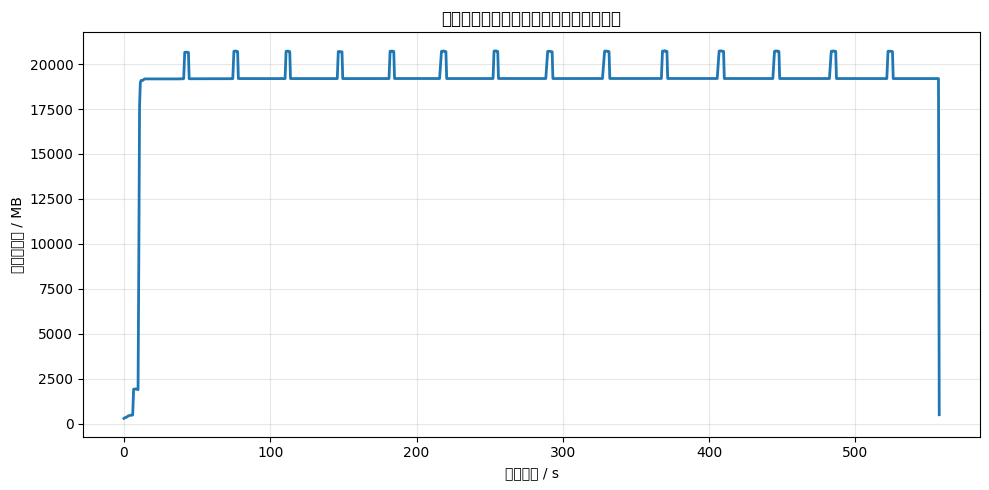

In [3]:
# Notebook 入口：直接改这里的配置，然后运行本 cell。
RUN_T_SOLVER_HARD2_VALIDATION = False
RUN_T_SOLVER_CROSSCHECK = False
RUN_T_SOLVER_CANDIDATE_SWEEP = False
T_PARTITION_CANDIDATES = [("hard", 2)]

cfg = MultiConfig(
    t_case_file="case_ACTIVSg25k.m",
    nD=500,
    mg_per_D=[3] * 500,
    mg_bus_count=46,
    target_total_nodes=100000,
)

index = synthesize_dataset_multi(cfg)
print(index["node_summary"])

# 只监控主流程
th = start_memory_monitor()
try:
    res = run_gmss_multi(
            t_solver="partitioned",
            t_partition_mode="soft",           # soft 边界 (等效阻抗弱连接，真 ADMM 协调)
            t_n_parts=4,                       # 4 区并行
            t_use_monolithic_warm_start=True,  # 单体牛拉 warm start
            t_admm_max_iter=8,
            t_admm_tol_vm=2e-3,                # 0.2% V 严格收敛容差
            t_admm_tol_va_deg=0.2,
            alpha=0.6, beta=0.6,               # GMSS 外环阻尼
        )
finally:
    stop_memory_monitor(th)

plot_memory_curve("长时序连续运行内存监控结果（主流程）")
